# Laboratorio 4 – Segmentación de imágenes con técnicas de agrupación

**Curso:** ISIS-2611 – Aprendizaje de Máquina

**Caso:** DermAlpes

**Autores:** Lucas Valbuena 202311538 y Juan Goyeneche 202320863

**Semestre:** 2026-02

## 0. Configuración del entorno

### 0.1 Importación de librerías

In [1]:
import os
import time
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from scipy import ndimage

from IPython.display import Markdown, display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler

from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.metrics import (silhouette_score, f1_score, v_measure_score,
                             precision_score, recall_score)

### 0.2 Configuración global de consideraciones

In [2]:
import warnings

warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'

*Se definieron como constantes los valores que se usan en todo el notebook, para que se puedan cambiar en un solo lugar. La semilla es la misma que usa `KMeans` en la práctica P11 (`random_state=0`), el rango de K es el del enunciado (de 2 a 8), y el ancho de las imágenes reducidas y el tamaño de la muestra para la silueta se justifican en las secciones 3.2 y 4.2.*

In [3]:
SEMILLA = 0            # semilla de K-medias, de la muestra de la silueta y de los bonos
ANCHO = 128            # ancho en píxeles al que se reducen imágenes y máscaras
TAMANO_MUESTRA = 2000  # píxeles usados para calcular el coeficiente de silueta
K_MIN, K_MAX = 2, 8    # rango de K que pide el enunciado

### 0.3 Carga de los datos

*Los datos se organizaron en la carpeta `data`, que está en el mismo directorio de este notebook. Dentro de ella hay dos subcarpetas, `ajuste` y `prueba`, que corresponden a la división indicada en el enunciado, 15 imágenes de ajuste y 5 de prueba. Cada subcarpeta contiene a su vez una carpeta `imagenes`, con las fotografías dermatoscópicas en formato `.jpg`, y una carpeta `mascaras`, con la máscara de referencia de cada imagen en formato `.png`.*

```
data/
├── ajuste/
│   ├── imagenes/   (15 imágenes ISIC_XXXXXXX.jpg)
│   └── mascaras/   (15 máscaras ISIC_XXXXXXX_Segmentation.png)
└── prueba/
    ├── imagenes/   (5 imágenes ISIC_XXXXXXX.jpg)
    └── mascaras/   (5 máscaras ISIC_XXXXXXX_Segmentation.png)
```

*Las imágenes se tomaron del conjunto de entrenamiento de la tarea de segmentación de lesiones de ISIC 2016 (`ISBI2016_ISIC_Part1_Training_Data`) y las máscaras, de su archivo de referencia (`ISBI2016_ISIC_Part1_Training_GroundTruth`). De ambos archivos solo se conservaron las 20 imágenes que indica el enunciado, y se mantuvieron sus nombres originales para que cualquier persona pueda reconstruir la carpeta a partir de la descarga oficial. Separar físicamente las imágenes de prueba de las de ajuste nos ayuda a cumplir la condición del laboratorio, porque durante la exploración y el ajuste del método solo se lee la carpeta `ajuste`, y la carpeta `prueba` se usa únicamente al final para calcular las métricas.*

*Para cargar las imágenes se reutilizó sin cambios la función `load_imgs` de la práctica P13, que recupera las rutas con `glob` y lee cada archivo con `cv2.imread` en formato RGB. Para las máscaras se escribió `load_masks`, que es la misma función pero lee el archivo en escala de grises con `cv2.IMREAD_GRAYSCALE` (documentación de OpenCV), porque cada máscara tiene un solo canal. En esta sección solo se cargan las imágenes de ajuste. Las de prueba se cargan hasta la sección 8, después de fijar la configuración final, para cumplir la condición del protocolo.*

In [4]:
img_paths_ajuste = sorted(glob(os.path.join('.', 'data', 'ajuste', 'imagenes', '*.jpg')))
mask_paths_ajuste = sorted(glob(os.path.join('.', 'data', 'ajuste', 'mascaras', '*.png')))

In [5]:
def load_imgs(paths):
  imgs = []
  for path in paths:
    imgs.append(cv2.imread(path, cv2.IMREAD_COLOR_RGB))
  return imgs

def load_masks(paths):
  masks = []
  for path in paths:
    masks.append(cv2.imread(path, cv2.IMREAD_GRAYSCALE))
  return masks

In [6]:
imgs_ajuste = load_imgs(img_paths_ajuste)
masks_ajuste = load_masks(mask_paths_ajuste)
nombres_ajuste = [os.path.basename(p).replace('.jpg', '') for p in img_paths_ajuste]

print(f"Imágenes de ajuste cargadas: {len(imgs_ajuste)}")
print(f"Máscaras de ajuste cargadas: {len(masks_ajuste)}")

Imágenes de ajuste cargadas: 15
Máscaras de ajuste cargadas: 15


## 1. Entendimiento del negocio y de los datos

### 1.1 Descripción del caso DermAlpes y objetivo del método

*DermAlpes es una empresa de telemedicina que conecta centros de salud de municipios pequeños con dermatólogos en las ciudades principales. El personal de los centros de salud toma fotografías de las lesiones de piel con un dermatoscopio y las envía para que un especialista las revise a distancia. La empresa quiere una herramienta que delimite automáticamente la lesión en cada foto, para que el dermatólogo pueda medir su tamaño y su forma y concentrarse en la zona relevante. La herramienta no diagnostica (como mencionamos en clase), solo delimita y guia.*

*DermAlpes no tiene imágenes etiquetadas, así que no puede entrenar un modelo supervisado. Por eso el objetivo de este laboratorio es evaluar si es posible segmentar la lesión sin supervisión, agrupando los píxeles de cada imagen con K-medias según su color y su posición, y construyendo a partir de esos grupos una máscara de la lesión. Para medir qué tan bien funciona, dónde falla y por qué, se usa un conjunto público de imágenes que sí tiene máscaras elaboradas por dermatólogos, que solo se usan para evaluar y nunca para agrupar los píxeles.*

### 1.2 Descripción del conjunto de datos (ISIC 2016)

*Se usan 20 imágenes dermatoscópicas del conjunto de entrenamiento de la tarea de segmentación de lesiones del reto ISIC 2016 (International Skin Imaging Collaboration). Cada imagen viene con una máscara de referencia hecha por especialistas, del mismo tamaño que la imagen, donde los píxeles de la lesión valen 255 y los de la piel o el fondo valen 0. La fuente se cita en la sección de referencias.*

*En este problema cada imagen es un conjunto de datos independiente y cada píxel es una instancia. Como en la práctica P13, una imagen de alto H y ancho W con tres canales se transforma en una tabla de H × W filas. Aquí cada fila tiene cinco características, los tres colores y las dos coordenadas del píxel. La máscara de referencia funciona como la etiqueta verdadera de cada píxel, pero K-medias no la ve, solo se usa al final para calcular las métricas.*

### 1.3 Separación en imágenes de ajuste y de prueba 

*El enunciado fija las 15 imágenes de ajuste y las 5 de prueba, iguales para todos los grupos. Las de ajuste se usan para todo lo que implique tomar decisiones, escoger los pesos β y λ, diseñar el criterio de la máscara y revisar los fallos. Las de prueba solo se usan una vez, al final, para estimar qué tan bien funcionaría el método con imágenes que no ha visto el modelo, que es lo que le pasaría a DermAlpes con las fotos nuevas de sus centros de salud. A continuación se verifica que las imágenes cargadas son exactamente las del enunciado y que no hay ninguna imagen repetida entre los dos conjuntos.*

In [7]:
IDS_AJUSTE = ['ISIC_0000085', 'ISIC_0000086', 'ISIC_0000089', 'ISIC_0000094', 'ISIC_0000108',
              'ISIC_0000114', 'ISIC_0000116', 'ISIC_0000122', 'ISIC_0000133', 'ISIC_0000137',
              'ISIC_0000150', 'ISIC_0000153', 'ISIC_0000156', 'ISIC_0000157', 'ISIC_0000112']
IDS_PRUEBA = ['ISIC_0000087', 'ISIC_0000105', 'ISIC_0000110', 'ISIC_0000123', 'ISIC_0000128']

# Las imágenes cargadas coinciden con las de ajuste del enunciado y no se cruzan con las de prueba
print("Ajuste coincide con el enunciado:", sorted(IDS_AJUSTE) == nombres_ajuste)
print("Máscaras en el mismo orden que las imágenes:",
      all(os.path.basename(m).startswith(n) for m, n in zip(mask_paths_ajuste, nombres_ajuste)))
print("Imágenes compartidas entre ajuste y prueba:", set(IDS_AJUSTE) & set(IDS_PRUEBA))

Ajuste coincide con el enunciado: True
Máscaras en el mismo orden que las imágenes: True
Imágenes compartidas entre ajuste y prueba: set()


## 2. Exploración de los datos

### 2.1 Dimensiones y formato de las imágenes y de las máscaras

*Siguiendo la idea de la práctica P13 de explorar primero la estructura de los datos, se revisaron las dimensiones de cada imagen, los valores que toman las máscaras, si cada máscara tiene el mismo tamaño que su imagen y qué porcentaje de la imagen ocupa la lesión.*

In [8]:
resumen_imgs = pd.DataFrame({
    'imagen': nombres_ajuste,
    'alto': [img.shape[0] for img in imgs_ajuste],
    'ancho': [img.shape[1] for img in imgs_ajuste],
    'canales': [img.shape[2] for img in imgs_ajuste],
    'valores_mascara': [np.unique(m).tolist() for m in masks_ajuste],
    'mismo_tamano_mascara': [img.shape[:2] == m.shape for img, m in zip(imgs_ajuste, masks_ajuste)],
    'pct_lesion': [round((m == 255).mean() * 100, 1) for m in masks_ajuste]
})
resumen_imgs

,imagen,alto,ancho,canales,valores_mascara,mismo_tamano_mascara,pct_lesion
0,ISIC_0000085,1536,2048,3,"[0, 255]",True,12.7
1,ISIC_0000086,1944,2592,3,"[0, 255]",True,23.4
2,ISIC_0000089,1536,2048,3,"[0, 255]",True,12.1
3,ISIC_0000094,1536,2048,3,"[0, 255]",True,5.9
4,ISIC_0000108,1536,2048,3,"[0, 255]",True,18.5
5,ISIC_0000112,1536,2048,3,"[0, 255]",True,20.2
6,ISIC_0000114,1536,2048,3,"[0, 255]",True,3.1
7,ISIC_0000116,1536,2048,3,"[0, 255]",True,36.1
8,ISIC_0000122,1536,2048,3,"[0, 255]",True,39.0
9,ISIC_0000133,1536,2048,3,"[0, 255]",True,14.2


In [9]:
resumen_imgs['pct_lesion'].describe().round(1)

count    15.0
mean     22.3
std      11.1
min       3.1
25%      13.4
50%      23.4
75%      31.8
max      39.0
Name: pct_lesion, dtype: float64

*Todas las imágenes están en RGB y cada máscara tiene exactamente el mismo tamaño y solo dos valores, 0 para la piel o el fondo y 255 para la lesión, como dice el enunciado. Los tamaños no son iguales, doce imágenes miden 2048 × 1536 píxeles, dos miden 2592 × 1944 y una (ISIC_0000157) mide 963 × 629. Por eso las imágenes se reducen en la sección 3.2 manteniendo su proporción.*

*El tamaño de la lesión cambia mucho de una imagen a otra. En una imagen ocupa apenas el 3,1% de la imagen y en otra el 39%, con un promedio de 22%. En la mayoría de las imágenes hay mucha más piel que lesión, así que cualquier píxel de piel marcado por error como lesión pesa bastante en el "Dice cuando la lesión es pequeña".*

### 2.2 Visualización de imágenes y máscaras de referencia

*Como el conjunto es pequeño, se visualizaron todas las imágenes y sus máscaras con la función `show_imgs` de la práctica P13. Se le hizo un solo cambio, en la práctica la cuadrícula se calcula como `len(imgs)//2` columnas, lo que solo funciona con un número par de imágenes; con 15 imágenes se perdería una. Por eso aquí se fija el número de columnas y se calcula el de filas, y se agregaron parámetros opcionales para poner el nombre de cada imagen y mostrar las máscaras en escala de grises.*

In [10]:
def show_imgs(imgs, title, cols=5, titles=None, cmap=None):
  rows = int(np.ceil(len(imgs) / cols))

  fig, ax = plt.subplots(rows, cols, layout='tight', figsize=(3 * cols, 2.6 * rows))
  ax = np.array(ax).reshape(rows, cols)

  img_idx = 0
  for i in range(rows):
    for j in range(cols):
      ax[i, j].axis('off')
      if img_idx < len(imgs):
        ax[i, j].imshow(imgs[img_idx], cmap=cmap)
        if titles is not None:
          ax[i, j].set_title(titles[img_idx], fontsize=9)
      img_idx += 1

  plt.suptitle(title)
  plt.show()

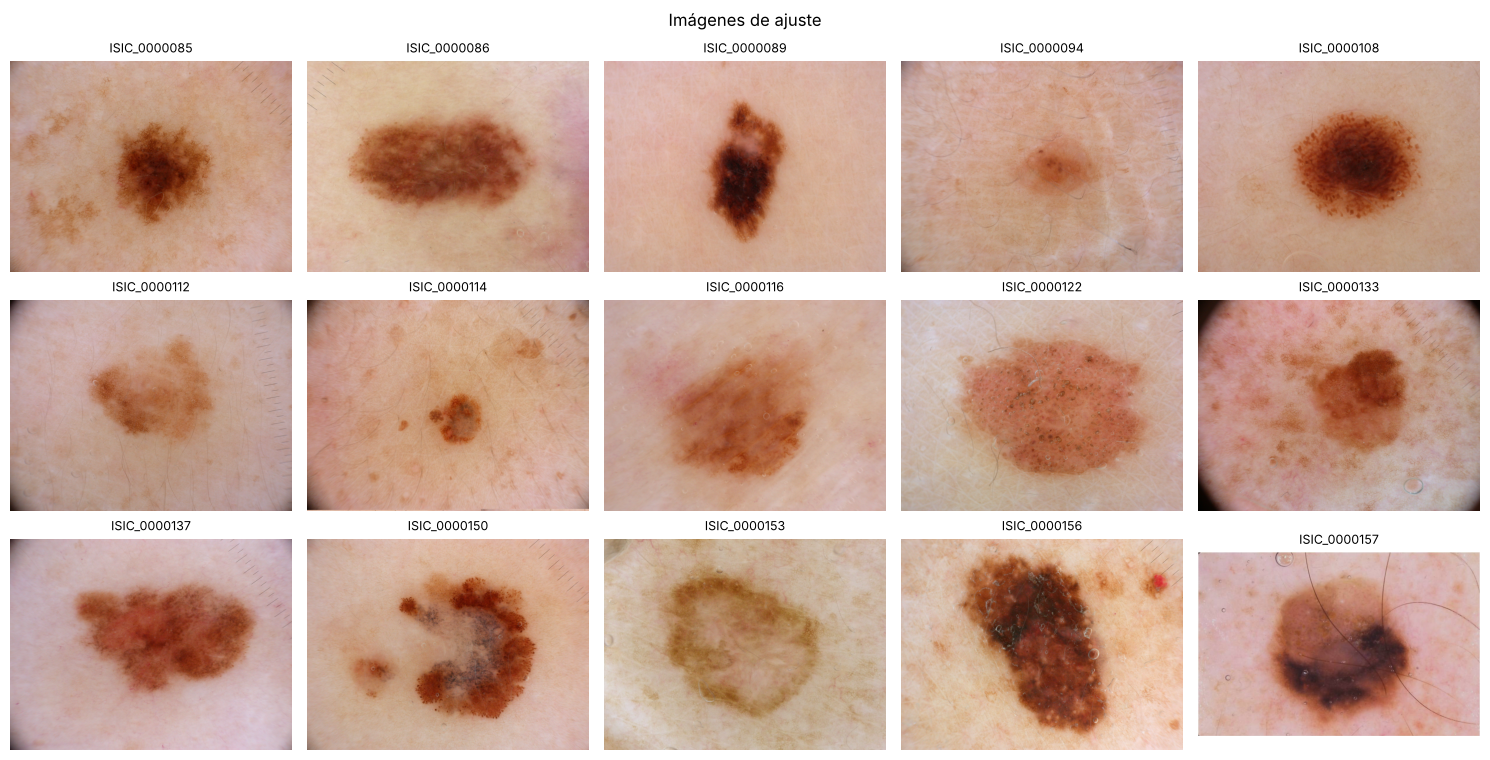

In [11]:
show_imgs(imgs_ajuste, 'Imágenes de ajuste', titles=nombres_ajuste)

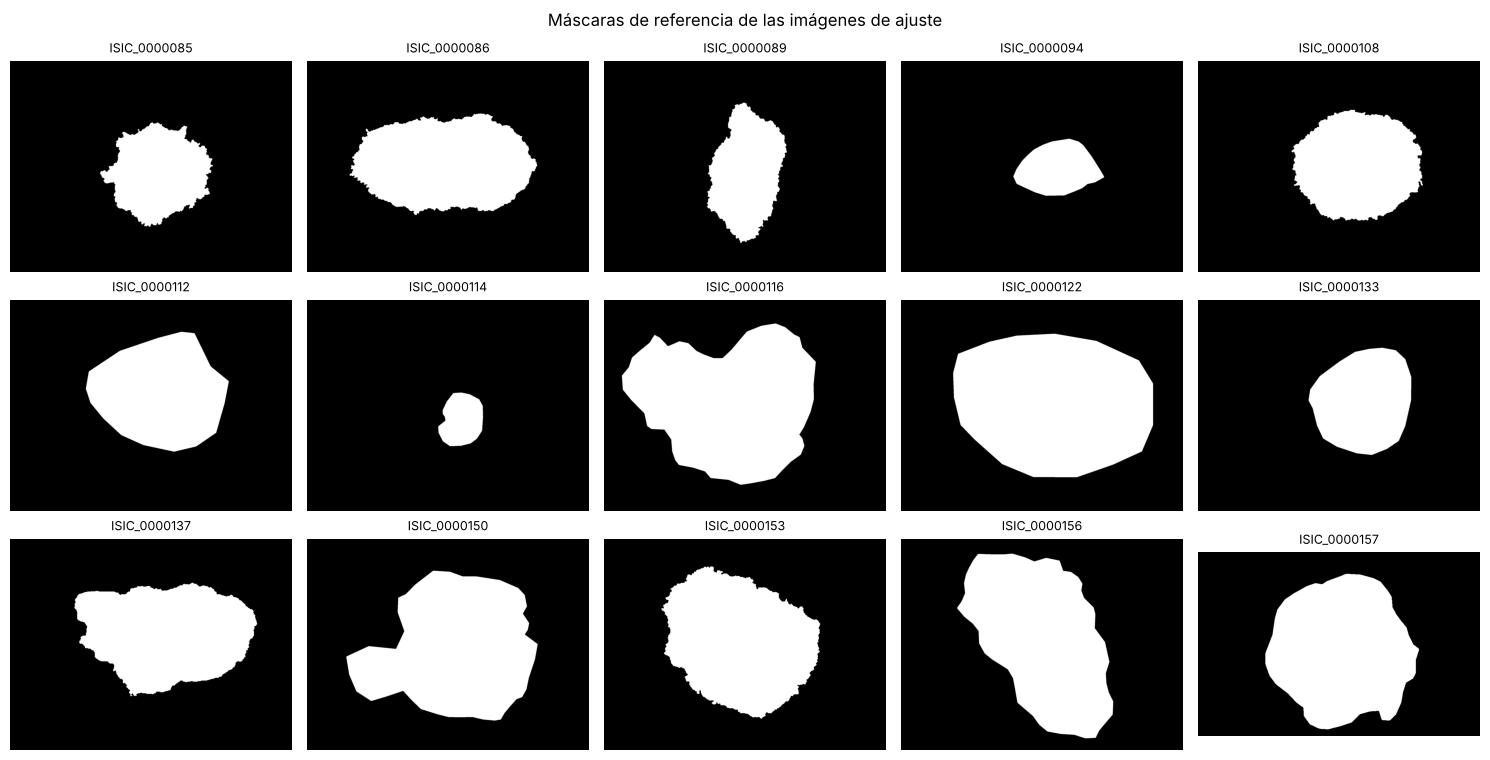

In [12]:
show_imgs(masks_ajuste, 'Máscaras de referencia de las imágenes de ajuste', titles=nombres_ajuste, cmap='gray')

*En casi todas las imágenes la lesión es una mancha café más oscura que la piel que la rodea, pero hay varios detalles que pueden confundir a un método que solo mira el color. En algunas fotos (por ejemplo ISIC_0000133) las esquinas están oscuras o negras por el borde circular del dermatoscopio. En otras hay pecas o manchas pequeñas alrededor de la lesión (ISIC_0000114 e ISIC_0000133), vellos (ISIC_0000157) o una regla de medición en el borde. Además, no todas las lesiones tienen un color uniforme, algunas tienen zonas claras o grisáceas en el centro (ISIC_0000150 e ISIC_0000153) o bordes muy claros que se confunden con la piel (ISIC_0000112 e ISIC_0000116). Las máscaras de referencia, en cambio, son regiones continuas que incluyen toda la lesión, también sus partes claras.*

## 3. Pipeline de preparación y representación

### 3.1 Preparación de las máscaras de referencia 

*Las máscaras se preparan como indica el enunciado. Primero se reducen al mismo tamaño que la imagen con `cv2.resize` usando  cv2.INTER_NEAREST`. Según la documentación de OpenCV, toma el valor del píxel original más cercano sin mezclarlo con sus vecinos, así que la máscara reducida sigue teniendo solo los valores 0 y 255. Después se dividen entre 255 para que la lesión quede como 1 y la piel como 0.*

In [13]:
def preparar_mascara(mask, ancho=ANCHO):
    alto = round(mask.shape[0] * ancho / mask.shape[1])
    # Vecino más cercano para que la máscara reducida conserve solo los valores 0 y 255
    mask_red = cv2.resize(mask, (ancho, alto), interpolation=cv2.INTER_NEAREST)
    # 0 (piel o fondo) -> 0 y 255 (lesión) -> 1
    return (mask_red // 255).astype(int)

### 3.2 Redimensionamiento de las imágenes

*La práctica P13 aplica K-medias sobre la imagen completa. Aquí eso no es viable, porque una imagen de 2048 × 1536 tiene más de tres millones de píxeles y el método se ejecuta 1.050 veces (10 combinaciones de pesos × 7 valores de K × 15 imágenes). Por eso todas las imágenes se redujeron a 128 píxeles de ancho conservando su proporción, lo que deja 128 × 96 = 12.288 píxeles en casi todas. Para reducir las imágenes se usó `cv2.INTER_AREA`, porque la documentación de OpenCV indica que es la interpolación que da mejores resultados al encoger una imagen. A esa resolución la lesión todavía se distingue bien y el porcentaje de lesión en las máscaras cambia como máximo 0,08 puntos, así que no se pierde información relevante para delimitarla.*

In [14]:
def reducir_imagen(img, ancho=ANCHO):
    alto = round(img.shape[0] * ancho / img.shape[1])
    return cv2.resize(img, (ancho, alto), interpolation=cv2.INTER_AREA)

In [15]:
imgs_aj = [reducir_imagen(img) for img in imgs_ajuste]
masks_aj = [preparar_mascara(m) for m in masks_ajuste]

print("Tamaños después de reducir:", sorted({img.shape for img in imgs_aj}))
print("Imagen y máscara con las mismas dimensiones:",
      all(img.shape[:2] == m.shape for img, m in zip(imgs_aj, masks_aj)))
print("Valores en las máscaras preparadas:", np.unique(np.concatenate([m.ravel() for m in masks_aj])))
print("Píxeles por imagen:", sorted({img.shape[0] * img.shape[1] for img in imgs_aj}))

Tamaños después de reducir: [(84, 128, 3), (96, 128, 3)]
Imagen y máscara con las mismas dimensiones: True
Valores en las máscaras preparadas: [0 1]
Píxeles por imagen: [10752, 12288]


In [16]:
pct_antes = [(m == 255).mean() * 100 for m in masks_ajuste]
pct_despues = [m.mean() * 100 for m in masks_aj]
print(f"Diferencia máxima en el porcentaje de lesión al reducir: {np.max(np.abs(np.array(pct_antes) - np.array(pct_despues))):.2f} puntos")

Diferencia máxima en el porcentaje de lesión al reducir: 0.08 puntos


### 3.3 Representación de cada píxel como [β·R, β·G, β·B, λ·x, λ·y] normalizada a [0, 1]

*Para representar cada píxel se reutilizó la idea de `spatial_img_segmentation` de la práctica P13, con `np.meshgrid` se obtienen la fila y la columna de cada píxel y se agregan como columnas a sus valores RGB. Hay dos diferencias. La primera es el orden de las coordenadas, el enunciado pide [R, G, B, x, y], donde x es la columna y y es la fila, mientras que en P13 se agregaba primero la fila. La segunda es cómo se aplican los pesos, en P13 solo se multiplicaban las coordenadas por `weight`, mientras que aquí la función `aplicar_pesos` multiplica los tres colores por β y las dos coordenadas por λ.*

*Para llevar color y posición al intervalo [0, 1] se usó `MinMaxScaler`, igual que en la práctica P11. Este escalador se ajusta en cada imagen por separado, así que lleva el píxel más oscuro y el más claro de cada canal a 0 y 1, y las coordenadas a x / (ancho − 1) y y / (alto − 1). Esto tiene una consecuencia que se tiene en cuenta en el análisis, el rango de color depende de cada imagen, de modo que en una foto con poco contraste las diferencias de color se estiran más que en una foto muy contrastada.*

In [17]:
def imagen_a_pixeles(img):
    # Coordenadas de cada píxel, igual que en spatial_img_segmentation de la práctica P13
    I, J = np.meshgrid(np.arange(img.shape[0]), np.arange(img.shape[1]), indexing='ij')
    X = img.reshape((-1, 3))
    # Columnas: R, G, B, x (columna) y y (fila)
    return np.hstack([X, J.reshape(-1, 1), I.reshape(-1, 1)]).astype(float)

def aplicar_pesos(X, beta=1.0, lam=0.0):
    # X ya está normalizada a [0, 1]: se multiplican los colores por beta y las coordenadas por lambda
    return X * np.array([beta, beta, beta, lam, lam])

### 3.4 Construcción del pipeline de Scikit-learn

*El pipeline sigue la estructura de la práctica P11, donde se encadenaban la imputación, el escalado y el modelo. Aquí el primer paso es un `FunctionTransformer`, como en los Laboratorios 1, 2 y 3, que convierte la imagen en la matriz de un píxel por fila. Luego `MinMaxScaler` normaliza las cinco columnas, un segundo `FunctionTransformer` aplica los pesos y el último paso es `KMeans` con los mismos parámetros de P11 (`max_iter=300` y `random_state=0`). No se usó `.set_output(transform="pandas")` como en P11 porque la entrada es una imagen y no un DataFrame con nombres de columnas.*

*Los pesos se cambian con `pipe.set_params(pesos__kw_args={'beta': β, 'lam': λ})` y el número de grupos con `pipe.set_params(model__n_clusters=k)`, el mismo mecanismo de la práctica P11. Así β y λ se pueden modificar sin cambiar la implementación, como pide el enunciado.*

In [18]:
kmeans = KMeans(max_iter=300, random_state=SEMILLA)

pipe = Pipeline(steps=[
    ("pixeles", FunctionTransformer(imagen_a_pixeles)),
    ("scaler", MinMaxScaler()),
    ("pesos", FunctionTransformer(aplicar_pesos, kw_args={'beta': 1.0, 'lam': 0.0})),
    ("model", kmeans)
])
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pixeles', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function ima...x7f811c379800>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary

*Para comprobar que el pipeline hace lo que pide el enunciado, se transformó la primera imagen de ajuste con tres combinaciones y se revisó el rango de cada columna. Igual que en la práctica P11, se usa `pipe[:-1]` para aplicar todos los pasos menos el modelo.*

In [19]:
columnas = ['β·R', 'β·G', 'β·B', 'λ·x', 'λ·y']
ejemplos = {'Solo color (β=1, λ=0)': (1, 0), 'Color y posición (β=1, λ=0.5)': (1, 0.5), 'Solo posición (β=0, λ=1)': (0, 1)}

for titulo, (beta, lam) in ejemplos.items():
    pipe.set_params(pesos__kw_args={'beta': beta, 'lam': lam})
    X_rep = pipe[:-1].fit_transform(imgs_aj[0])
    display(Markdown(f"**{titulo}** — matriz de {X_rep.shape[0]} píxeles × {X_rep.shape[1]} características"))
    display(pd.DataFrame(X_rep, columns=columnas).describe().loc[['min', 'max']].round(3))

**Solo color (β=1, λ=0)** — matriz de 12288 píxeles × 5 características

,β·R,β·G,β·B,λ·x,λ·y
min,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,0.0,0.0


**Color y posición (β=1, λ=0.5)** — matriz de 12288 píxeles × 5 características

,β·R,β·G,β·B,λ·x,λ·y
min,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,0.5,0.5


**Solo posición (β=0, λ=1)** — matriz de 12288 píxeles × 5 características

,β·R,β·G,β·B,λ·x,λ·y
min,0.0,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,1.0,1.0


## 4. Agrupación y selección de K

### 4.1 Combinaciones de β y λ (razones λ/β, incluyendo solo color y solo posición)

In [20]:
COMBINACIONES = [(1, 0), (1, 0.1), (1, 0.25), (1, 0.5), (1, 0.75),
                 (1, 1), (1, 1.5), (1, 2), (1, 4), (0, 1)]

def nombre_config(beta, lam):
    if lam == 0:
        return f"β={beta:g}, λ={lam:g} (solo color)"
    if beta == 0:
        return f"β={beta:g}, λ={lam:g} (solo posición)"
    return f"β={beta:g}, λ={lam:g}"

pd.DataFrame({'β': [b for b, l in COMBINACIONES],
              'λ': [l for b, l in COMBINACIONES],
              'λ/β': [l / b if b != 0 else np.inf for b, l in COMBINACIONES],
              'configuración': [nombre_config(b, l) for b, l in COMBINACIONES]})

,β,λ,λ/β,configuración
0,1,0.00,0.00,"β=1, λ=0 (solo color)"
1,1,0.10,0.10,"β=1, λ=0.1"
2,1,0.25,0.25,"β=1, λ=0.25"
3,1,0.50,0.50,"β=1, λ=0.5"
4,1,0.75,0.75,"β=1, λ=0.75"
5,1,1.00,1.00,"β=1, λ=1"
6,1,1.50,1.50,"β=1, λ=1.5"
7,1,2.00,2.00,"β=1, λ=2"
8,1,4.00,4.00,"β=1, λ=4"
9,0,1.00,inf,"β=0, λ=1 (solo posición)"


### 4.2 Muestra reproducible de píxeles para la silueta (tamaño de la muestra y semilla)

*El coeficiente de silueta compara la distancia de cada píxel a los de su propio grupo con la distancia a los del grupo más cercano, así que el tiempo para calcularlo crece con el cuadrado del número de píxeles. En la práctica P11 se calculaba sobre todos los datos, pero aquí se calcula 1.050 veces. Por eso se usó una muestra de 2.000 píxeles por imagen, alrededor del 16% de cada imagen reducida, con los parámetros `sample_size` y `random_state` de `silhouette_score`. Según la documentación de scikit-learn, `sample_size` calcula el coeficiente sobre un subconjunto aleatorio de los datos y `random_state` fija ese subconjunto para que el resultado sea reproducible. La semilla es 0, la misma que se usa para K-medias.*

In [21]:
n_pixeles = imgs_aj[0].shape[0] * imgs_aj[0].shape[1]
print(f"Píxeles por imagen reducida: {n_pixeles}")
print(f"Tamaño de la muestra para la silueta: {TAMANO_MUESTRA} píxeles ({TAMANO_MUESTRA / n_pixeles:.0%} de la imagen)")
print(f"Semilla de la muestra: {SEMILLA}")

Píxeles por imagen reducida: 12288
Tamaño de la muestra para la silueta: 2000 píxeles (16% de la imagen)
Semilla de la muestra: 0


### 4.3 K-medias con K entre 2 y 8 y selección de K mediante el coeficiente de silueta

*La función `evaluar_k` es una adaptación de la función con el mismo nombre de la práctica P11. Se conservaron los mismos pasos, cambiar K con `set_params`, ajustar el pipeline completo, obtener los datos ya transformados con `pipe[:-1].transform` y calcular la silueta con las etiquetas del modelo. Las diferencias son que recibe una imagen en lugar de un DataFrame, que la silueta se calcula sobre la muestra de la sección 4.2, que no grafica la inercia porque el enunciado pide seleccionar K solo con la silueta, y que devuelve las etiquetas de cada K para poder construir después las máscaras sin volver a ejecutar K-medias.*

*Una aclaración sobre cómo se busca K. En los laboratorios anteriores los hiperparámetros se buscaban con `GridSearchCV`, pero aquí no se usa, igual que en las prácticas P11 y P13. `GridSearchCV` está pensado para aprendizaje supervisado, divide los datos en particiones de entrenamiento y validación y mide qué tan bien el modelo predice los datos que no vio. En la segmentación no hay etiquetas que predecir y cada imagen se agrupa con todos sus píxeles, así que separar los píxeles en particiones no tiene sentido. Además, si no se le da otra métrica, `GridSearchCV` califica a K-medias con su inercia, que siempre mejora al aumentar K, así que elegiría siempre el K más grande. Por eso K se busca con un ciclo, que es el equivalente a una búsqueda en rejilla sin validación cruzada, se prueba cada valor de K entre 2 y 8, se entrena K-medias con todos los píxeles de la imagen, se calcula la silueta y se elige el K con la silueta más alta.*

In [22]:
def evaluar_k(img, k_min=K_MIN, k_max=K_MAX):
    """
    Calcula el coeficiente de la silueta para cada valor de k sobre una imagen

    Parametros:
    img : np.ndarray
        Imagen RGB reducida (alto x ancho x 3)
    k_min : int
        Valor mínimo para k
    k_max : int
        Valor máximo para k
    """
    ks = list(range(k_min, k_max + 1))
    siluetas, etiquetas = [], []
    for i in ks:
        # Modificamos el parámetro k
        pipe.set_params(model__n_clusters=i)
        # Ejecutamos el pipeline completo: representación, normalización, pesos y KMeans
        pipe.fit(img)
        # Reutilizamos el pipeline para obtener la matriz de píxeles ya transformada
        clean_data = pipe[:-1].transform(img)
        # Calculamos el coeficiente de la silueta sobre una muestra reproducible de píxeles
        siluetas.append(silhouette_score(clean_data, pipe['model'].labels_,
                                         sample_size=TAMANO_MUESTRA, random_state=SEMILLA))
        etiquetas.append(pipe['model'].labels_.astype(np.int8))
    return ks, siluetas, etiquetas

*Antes de ejecutar todas las combinaciones, se graficó la silueta de tres imágenes para dos configuraciones, como en la gráfica de la silueta de la práctica P11.*

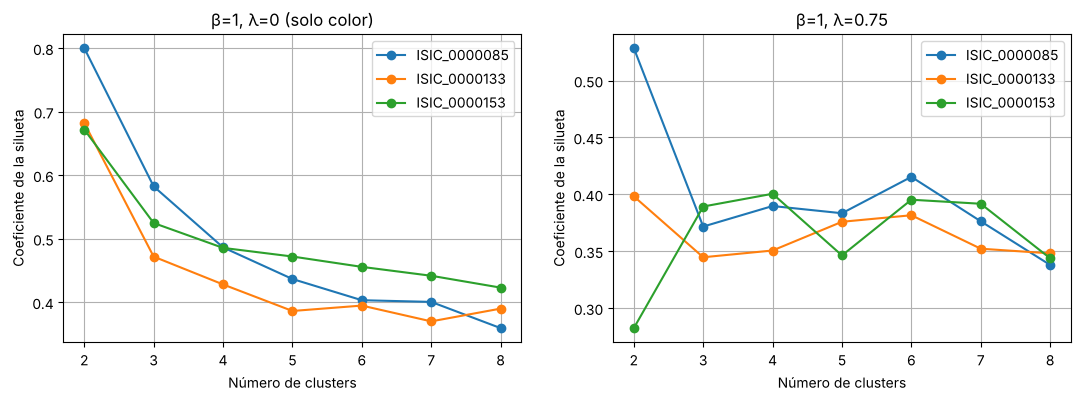

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (beta, lam) in zip(axes, [(1, 0), (1, 0.75)]):
    pipe.set_params(pesos__kw_args={'beta': beta, 'lam': lam})
    for nombre in ['ISIC_0000085', 'ISIC_0000133', 'ISIC_0000153']:
        idx = nombres_ajuste.index(nombre)
        ks, siluetas, _ = evaluar_k(imgs_aj[idx])
        ax.plot(ks, siluetas, marker='o', label=nombre)
    ax.set(xlabel='Número de clusters', ylabel='Coeficiente de la silueta', title=nombre_config(beta, lam))
    ax.legend()
    ax.grid()
plt.show()

*En las gráficas se ven dos comportamientos distintos. Con solo color, la silueta baja a medida que aumenta K en las tres imágenes, así que siempre se elige K = 2, el color separa naturalmente la imagen en una parte oscura y una clara. Al agregar la posición la curva deja de ser decreciente y el máximo puede quedar en otro K, como en ISIC_0000153, donde está en K = 4. Esto pasa porque la posición agrega una estructura que no depende del color, los píxeles de distintas zonas de la imagen se separan aunque tengan el mismo color.*

*Ahora se ejecuta K-medias con K entre 2 y 8 para las 10 combinaciones y las 15 imágenes de ajuste, y para cada combinación e imagen se queda el K con mayor silueta.*

In [24]:
resultados_k = []      # silueta de cada K, para cada combinación e imagen
etiquetas_todas = {}   # etiquetas de cada K: (beta, lam, imagen) -> lista de etiquetas

inicio = time.time()
for beta, lam in COMBINACIONES:
    pipe.set_params(pesos__kw_args={'beta': beta, 'lam': lam})
    for nombre, img in zip(nombres_ajuste, imgs_aj):
        ks, siluetas, etiquetas = evaluar_k(img)
        etiquetas_todas[(beta, lam, nombre)] = etiquetas
        for k, s in zip(ks, siluetas):
            resultados_k.append({'beta': beta, 'lam': lam, 'imagen': nombre, 'K': k, 'silueta': s})
print(f"Tiempo total: {time.time() - inicio:.0f} s ({len(resultados_k)} ejecuciones de K-medias)")

df_k = pd.DataFrame(resultados_k)
# Para cada combinación e imagen se elige el K con mayor silueta
idx_mejor = df_k.groupby(['beta', 'lam', 'imagen'])['silueta'].idxmax()
df_sel = df_k.loc[idx_mejor].reset_index(drop=True)
df_sel['configuración'] = [nombre_config(b, l) for b, l in zip(df_sel['beta'], df_sel['lam'])]

Tiempo total: 55 s (1050 ejecuciones de K-medias)


In [25]:
tabla_k = df_sel.pivot_table(index='imagen', columns='configuración', values='K', sort=False)
tabla_k = tabla_k[[nombre_config(b, l) for b, l in COMBINACIONES]]
tabla_k

configuración,"β=1, λ=0 (solo color)","β=1, λ=0.1","β=1, λ=0.25","β=1, λ=0.5","β=1, λ=0.75","β=1, λ=1","β=1, λ=1.5","β=1, λ=2","β=1, λ=4","β=0, λ=1 (solo posición)"
imagen,,,,,,,,,,
ISIC_0000085,2.0,2.0,2.0,2.0,2.0,6.0,5.0,5.0,5.0,4.0
ISIC_0000086,2.0,2.0,2.0,2.0,2.0,5.0,5.0,5.0,5.0,4.0
ISIC_0000089,2.0,2.0,2.0,2.0,2.0,6.0,5.0,5.0,5.0,4.0
ISIC_0000094,2.0,2.0,2.0,5.0,5.0,5.0,5.0,5.0,4.0,4.0
ISIC_0000108,2.0,2.0,2.0,2.0,2.0,2.0,6.0,5.0,5.0,4.0
ISIC_0000112,2.0,2.0,2.0,5.0,5.0,5.0,5.0,5.0,4.0,4.0
ISIC_0000114,2.0,2.0,2.0,5.0,5.0,4.0,5.0,4.0,4.0,4.0
ISIC_0000116,2.0,2.0,2.0,2.0,2.0,5.0,5.0,5.0,5.0,4.0
ISIC_0000122,2.0,2.0,2.0,2.0,5.0,5.0,5.0,5.0,5.0,4.0


In [26]:
df_sel.groupby('configuración', sort=False)[['K', 'silueta']].agg(['mean', 'min', 'max']).round(3)

K         silueta              
                           mean min max    mean    min    max
configuración                                                
β=0, λ=1 (solo posición)  4.000   4   4   0.414  0.407  0.415
β=1, λ=0 (solo color)     2.000   2   2   0.743  0.635  0.863
β=1, λ=0.1                2.000   2   2   0.726  0.614  0.847
β=1, λ=0.25               2.000   2   2   0.672  0.543  0.797
β=1, λ=0.5                2.600   2   5   0.546  0.348  0.699
β=1, λ=0.75               2.933   2   5   0.480  0.372  0.602
β=1, λ=1                  4.667   2   8   0.441  0.360  0.477
β=1, λ=1.5                5.133   5   6   0.443  0.384  0.474
β=1, λ=2                  4.933   4   5   0.442  0.394  0.470
β=1, λ=4                  4.733   4   5   0.419  0.396  0.443

*La silueta elige K = 2 en todas las imágenes cuando el peso de la posición es bajo (λ/β ≤ 0,25), y en esas configuraciones alcanza los valores más altos, con un promedio de 0,74 en la de solo color. A partir de λ/β = 0,5 aparecen imágenes con K = 4 o 5, y con λ/β ≥ 1 el K elegido casi siempre está entre 4 y 6, mientras la silueta promedio baja a valores entre 0,42 y 0,44. Es decir, al aumentar el peso de la posición los grupos quedan menos separados y la silueta prefiere dividir la imagen en más zonas.*

*La configuración de solo posición es un caso especial, elige K = 4 en todas las imágenes con prácticamente la misma silueta (0,41). Esto tiene sentido, porque sin color todas las imágenes son la misma cuadrícula de 128 × 96 puntos, y K-medias la divide en cuatro cuadrantes sin importar lo que muestre la foto. Solo ISIC_0000157 cambia un poco, porque su cuadrícula es de 128 × 84.*

## 5. Construcción de la máscara de la lesión

### 5.1 Criterio para identificar el grupo de la lesión: el grupo más oscuro

*K-medias agrupa los píxeles, pero no dice cuál grupo es la lesión. El criterio elegido es seleccionar el grupo más oscuro, para cada grupo se calcula el brillo promedio de sus píxeles, entendido como el promedio de R, G y B en la escala original de 0 a 255, y se marca como lesión el grupo con menor brillo. El brillo se calcula sobre los colores originales y no sobre los centroides, porque los centroides están en el espacio normalizado y multiplicado por los pesos. Con β = 0 los centroides ni siquiera tienen información de color, y así el criterio funciona igual para todas las configuraciones.*

In [27]:
def grupo_mas_oscuro(img, etiquetas):
    # Brillo de cada píxel: promedio de R, G y B en la escala original (0 a 255)
    brillo = imagen_a_pixeles(img)[:, :3].mean(axis=1)
    grupos = np.unique(etiquetas)
    brillo_grupos = [brillo[etiquetas == g].mean() for g in grupos]
    return grupos[int(np.argmin(brillo_grupos))]

def construir_mascara(img, etiquetas):
    grupo = grupo_mas_oscuro(img, etiquetas)
    return (etiquetas == grupo).astype(int).reshape(img.shape[:2])

### 5.2 Construcción de la máscara binaria

*La máscara binaria tiene 1 en los píxeles del grupo elegido y 0 en todos los demás, con el mismo tamaño de la imagen reducida para poder compararla con la máscara de referencia. La función `segmentar` junta todos los pasos del método para una imagen, fija β y λ en el pipeline, elige K con la silueta (o usa un K fijo, lo que se necesita para la actividad de verificación) y construye la máscara. Es la función que se aplica tal cual a las imágenes de prueba en la sección 8.*

In [28]:
def segmentar(img, beta, lam, k_fijo=None):
    """Aplica el método completo a una imagen: K por silueta (o K fijo), K-medias y máscara del grupo más oscuro"""
    pipe.set_params(pesos__kw_args={'beta': beta, 'lam': lam})
    if k_fijo is None:
        ks, siluetas, etiquetas = evaluar_k(img)
        idx = int(np.argmax(siluetas))
        k, silueta, etiq = ks[idx], siluetas[idx], etiquetas[idx]
    else:
        ks, siluetas, etiquetas = evaluar_k(img, k_fijo, k_fijo)
        k, silueta, etiq = k_fijo, siluetas[0], etiquetas[0]
    return {'K': k, 'silueta': silueta, 'etiquetas': etiq, 'mascara': construir_mascara(img, etiq)}

*Para ver cómo funciona el criterio se adaptó la función `get_img_masks` de la práctica P13, que muestra una máscara por cada grupo. Aquí recibe las etiquetas ya calculadas, muestra el brillo promedio de cada grupo y marca en rojo el grupo que el criterio elige como lesión. Como ejemplo se tomó la imagen con más grupos en la configuración β = 1, λ = 0,5.*

In [29]:
def get_img_masks(img, etiquetas):
  segmented_img = etiquetas.reshape(img.shape[:2])
  brillo = imagen_a_pixeles(img)[:, :3].mean(axis=1)
  grupos = np.unique(etiquetas)
  elegido = grupo_mas_oscuro(img, etiquetas)

  fig, ax = plt.subplots(1, len(grupos) + 1, layout='tight', figsize=(3 * (len(grupos) + 1), 3))
  ax[0].imshow(img)
  ax[0].set(title='Imagen original')
  for g in grupos:
    mask = (segmented_img == g)
    ax[g + 1].imshow(mask, cmap='gray')
    titulo = f'Label = {g}\nbrillo = {brillo[etiquetas == g].mean():.0f}'
    ax[g + 1].set_title(titulo + (' (lesión)' if g == elegido else ''), color='red' if g == elegido else 'black')
  for a in ax:
    a.axis('off')
  plt.show()

Imagen: ISIC_0000094, configuración β=1, λ=0.5, K elegido por silueta = 5


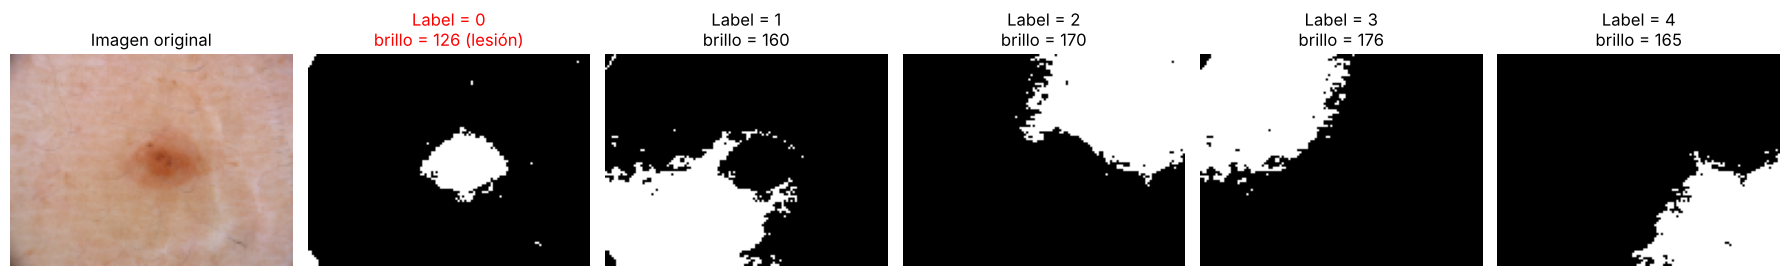

In [30]:
# Ejemplo ilustrativo: imagen con el mayor K elegido por silueta en la configuración β=1, λ=0.5
sel_ej = df_sel[(df_sel['beta'] == 1) & (df_sel['lam'] == 0.5)]
nombre_ej = sel_ej.sort_values(['K', 'imagen'], ascending=[False, True]).iloc[0]['imagen']
k_ej = int(sel_ej.set_index('imagen').loc[nombre_ej, 'K'])
idx_ej = nombres_ajuste.index(nombre_ej)
etiq_ej = etiquetas_todas[(1, 0.5, nombre_ej)][k_ej - K_MIN]

print(f"Imagen: {nombre_ej}, configuración β=1, λ=0.5, K elegido por silueta = {k_ej}")
get_img_masks(imgs_aj[idx_ej], etiq_ej)

*En ISIC_0000094 la silueta eligió K = 5. La lesión quedó en el grupo 0, que es claramente el más oscuro (brillo promedio de 126, frente a valores entre 160 y 176 en los demás grupos), y los otros cuatro grupos dividen la piel en zonas de la imagen. El ejemplo muestra que el criterio funciona aunque K sea mayor que 2, la piel queda repartida en varios grupos, pero solo uno contiene la lesión.*

### 5.3 Justificación del criterio

*El criterio se basa en lo que se observó en la exploración, en casi todas las imágenes la lesión es una mancha café o marrón claramente más oscura que la piel. Además, es un criterio simple y fácil de explicar a DermAlpes, no necesita ajustar ningún umbral con las máscaras de referencia y funciona igual con cualquier K.*

*El criterio tiene limitaciones que se anticipan desde la exploración. Si en la foto hay algo más oscuro que la lesión, ese será el grupo elegido. Si la lesión tiene zonas claras, esas zonas quedan en otro grupo y no entran en la máscara. Y como se elige un solo grupo, cuando K es grande y la lesión se divide en varios grupos de distintos tonos de café, solo se marca la parte más oscura. Estas limitaciones se revisan con los resultados en las secciones 7.3 y 8.5.*

## 6. Actividad de verificación con IAG

### 6.1 Consulta a la IAG (sin anexar imágenes ni mencionar el nombre del conjunto)

*Antes de elegir la configuración final se consultó a Claude (Anthropic) en una sesión aparte de claude.ai, abierta desde el navegador y sin acceso a nuestros archivos. Como pide el enunciado, la consulta no incluyó imágenes ni el nombre del conjunto de datos, las imágenes se describieron con palabras, junto con el método que no se puede cambiar. El historial completo de la conversación se adjunta en la entrega. El prompt utilizado fue el siguiente:*

```
Necesito una recomendación para un laboratorio de aprendizaje no supervisado. Responde solo a partir de esta descripción; no busques ni abras archivos.

Tengo fotografías de lesiones de piel tomadas con un dermatoscopio y quiero segmentar la lesión agrupando los píxeles con K-medias, sin entrenar un modelo supervisado.

Así son las imágenes:
- La mayoría muestra una mancha café o marrón sobre piel clara, más o menos en el centro.
- La lesión ocupa entre el 3% y el 40% de la imagen.
- Algunas lesiones tienen bordes de un café muy claro o zonas centrales claras o grisáceas.
- En algunas fotos las esquinas o el borde se ven negros por la forma circular del lente.
- Algunas tienen pecas, vellos o una regla de medición alrededor de la lesión.

Así es el método:
- Las imágenes se reducen a 128 píxeles de ancho.
- Cada píxel se representa como [β·R, β·G, β·B, λ·x, λ·y], con las cinco columnas normalizadas a [0, 1] con MinMaxScaler en cada imagen.
- Se aplica K-medias con K entre 2 y 8, y K se elige con el coeficiente de silueta.
- Hay que decidir automáticamente qué grupos son la lesión para construir una máscara binaria, que se evalúa con el coeficiente de Dice frente a una máscara hecha por un dermatólogo.

¿Qué valores de β, λ y K me recomiendas, y qué criterio usarías para identificar los grupos de la lesión y construir la máscara? Justifica brevemente.
```

### 6.2 Recomendación obtenida (β, λ, K y criterio de construcción de la máscara)

*La IAG empezó advirtiendo que, si los pesos se aplican antes de `MinMaxScaler`, el escalado los anula, y que el orden correcto es normalizar primero y multiplicar después. Nuestro pipeline ya está en ese orden (sección 3.4). Luego recomendó β = 1 y λ ≈ 0,3, dentro de un rango de 0,2 a 0,5, con el argumento de que el color debe dominar y un poco de posición ayuda a separar de la lesión las esquinas oscuras y las pecas. Para K recomendó mantener la silueta, pero advirtió que tiende a elegir K = 2, lo que junta la lesión con el viñeteado y deja los bordes claros con la piel.*

*Su criterio para la máscara es más elaborado que el nuestro. Primero descarta los grupos casi negros que están en el borde de la imagen, que corresponden al viñeteado. Luego identifica la piel como el grupo claro que más toca el borde, y marca como lesión todos los grupos que sean al menos 15–20% más oscuros que la piel y tengan pocos píxeles en el borde. Después une esos grupos y aplica una limpieza, una apertura morfológica, conservar solo la región conectada más cercana al centro, rellenar los huecos, un cierre y una comprobación de que el área quede entre el 3% y el 40% de la imagen. También sugirió dos cambios al preprocesamiento, un filtro de mediana y excluir el negro del borde antes de `MinMaxScaler`, que no se probaron porque cambian el método que define el enunciado.*

### 6.3 Prueba de la recomendación en las imágenes de ajuste

*La recomendación se probó con las 15 imágenes de ajuste en dos partes, para separar el efecto de λ del efecto del criterio. Primero se aplicó λ = 0,3 con nuestro criterio del grupo más oscuro, usando la misma función `segmentar` del método. Después se implementó el criterio de la IAG y se aplicó tanto con λ = 0,3 como con λ = 0,75, que es la configuración con mayor Dice de la sección 7.*

*La IAG no dio valores exactos para varios umbrales, así que los fijamos antes de ver los resultados, el borde es el 10% exterior de la imagen, un grupo es casi negro si su brillo promedio es menor que 60 (en la escala de 0 a 255), un grupo de lesión debe ser al menos 15% más oscuro que la piel y tener menos del 20% de sus píxeles en el borde, y las operaciones morfológicas usan un núcleo de 3 × 3 píxeles. Las operaciones de limpieza no están en las prácticas del curso, así que se hicieron con la documentación oficial, la apertura y el cierre con `cv2.morphologyEx`, las regiones conectadas con `cv2.connectedComponentsWithStats` (OpenCV) y el relleno de huecos con `binary_fill_holes` (SciPy).*

In [31]:
# Recomendación de la IAG: β = 1, λ = 0,3 y K elegido por silueta
BETA_IAG, LAMBDA_IAG, K_IAG = 1, 0.3, None

# Segmentación con la λ de la IAG y con λ = 0,75 (mismo K por silueta en ambos casos)
segs_iag = {lam: [segmentar(img, BETA_IAG, lam, k_fijo=K_IAG) for img in imgs_aj] for lam in [LAMBDA_IAG, 0.75]}

In [32]:
def borde_imagen(alto, ancho, frac=0.10):
    # Píxeles en el 10% exterior de la imagen, en el mismo orden de imagen_a_pixeles
    borde = np.zeros((alto, ancho), dtype=bool)
    bh, bw = max(1, round(alto * frac)), max(1, round(ancho * frac))
    borde[:bh, :] = borde[-bh:, :] = True
    borde[:, :bw] = borde[:, -bw:] = True
    return borde.ravel()

def criterio_iag(img, etiquetas, brillo_negro=60, frac_oscuro=0.85, max_borde=0.20):
    alto, ancho = img.shape[:2]
    brillo = imagen_a_pixeles(img)[:, :3].mean(axis=1)
    borde = borde_imagen(alto, ancho)
    grupos = np.unique(etiquetas)
    B = {g: brillo[etiquetas == g].mean() for g in grupos}   # brillo promedio del grupo
    F = {g: borde[etiquetas == g].mean() for g in grupos}    # fracción del grupo en el borde

    # 1. Descartar el viñeteado: grupos casi negros con la mayoría de sus píxeles en el borde
    restantes = [g for g in grupos if not (B[g] < brillo_negro and F[g] > 0.5)] or list(grupos)
    # 2. Piel: entre los grupos claros, el que más toca el borde
    claros = [g for g in restantes if B[g] >= np.median([B[x] for x in restantes])]
    piel = max(claros, key=lambda g: F[g])
    # 3. Lesión: grupos al menos 15% más oscuros que la piel y con pocos píxeles en el borde
    lesion = [g for g in restantes if g != piel and B[g] <= frac_oscuro * B[piel] and F[g] < max_borde]

    def limpiar(grupos_lesion):
        nucleo = np.ones((3, 3), np.uint8)
        m = np.isin(etiquetas, grupos_lesion).reshape(alto, ancho).astype(np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, nucleo)                 # apertura
        n, regiones, stats, centros = cv2.connectedComponentsWithStats(m)
        if n > 1:                                                       # región más cercana al centro
            dist = [np.hypot(centros[r][0] - ancho / 2, centros[r][1] - alto / 2) for r in range(1, n)]
            m = (regiones == 1 + int(np.argmin(dist))).astype(np.uint8)
        m = ndimage.binary_fill_holes(m).astype(np.uint8)              # rellenar huecos
        return cv2.morphologyEx(m, cv2.MORPH_CLOSE, nucleo)            # cierre

    m = limpiar(lesion)
    # Comprobación de área: entre el 3% y el 40% de la imagen
    if m.mean() > 0.40 and len(lesion) > 1:
        m = limpiar(sorted(lesion, key=lambda g: B[g])[:-1])            # quitar el grupo de lesión más claro
    elif m.mean() < 0.03:
        candidatos = sorted([g for g in restantes if g not in lesion and g != piel], key=lambda g: B[g])
        if candidatos:
            m = limpiar(lesion + [candidatos[0]])                       # añadir el siguiente grupo más oscuro
    return m.astype(int)

In [33]:
filas_iag = []
for idx, (nombre, mask) in enumerate(zip(nombres_ajuste, masks_aj)):
    img = imgs_aj[idx]
    r03, r075 = segs_iag[LAMBDA_IAG][idx], segs_iag[0.75][idx]
    filas_iag.append({
        'imagen': nombre, 'K (λ=0.3)': r03['K'], 'K (λ=0.75)': r075['K'],
        'λ=0.75 + grupo más oscuro (nuestra)': f1_score(mask.ravel(), r075['mascara'].ravel()),
        'λ=0.3 + grupo más oscuro': f1_score(mask.ravel(), r03['mascara'].ravel()),
        'λ=0.3 + criterio IAG (recomendación completa)': f1_score(mask.ravel(), criterio_iag(img, r03['etiquetas']).ravel()),
        'λ=0.75 + criterio IAG': f1_score(mask.ravel(), criterio_iag(img, r075['etiquetas']).ravel())})
df_iag = pd.DataFrame(filas_iag)
display(df_iag.round(3))
df_iag.drop(columns=['imagen', 'K (λ=0.3)', 'K (λ=0.75)']).agg(['mean', 'std', 'min']).T.round(3)

,imagen,K (λ=0.3),K (λ=0.75),λ=0.75 + grupo más oscuro (nuestra),λ=0.3 + grupo más oscuro,λ=0.3 + criterio IAG (recomendación completa),λ=0.75 + criterio IAG
0,ISIC_0000085,2,2,0.896,0.896,0.895,0.895
1,ISIC_0000086,2,2,0.924,0.924,0.917,0.918
2,ISIC_0000089,2,2,0.940,0.940,0.941,0.941
3,ISIC_0000094,2,5,0.889,0.796,0.917,0.923
4,ISIC_0000108,2,2,0.909,0.907,0.896,0.895
5,ISIC_0000112,2,5,0.772,0.741,0.780,0.782
6,ISIC_0000114,2,5,0.739,0.578,0.862,0.855
7,ISIC_0000116,2,2,0.748,0.750,0.746,0.744
8,ISIC_0000122,2,5,0.881,0.898,0.892,0.873
9,ISIC_0000133,2,2,0.731,0.737,0.888,0.885


,mean,std,min
λ=0.75 + grupo más oscuro (nuestra),0.857,0.076,0.731
λ=0.3 + grupo más oscuro,0.841,0.104,0.578
λ=0.3 + criterio IAG (recomendación completa),0.881,0.066,0.746
λ=0.75 + criterio IAG,0.874,0.062,0.744


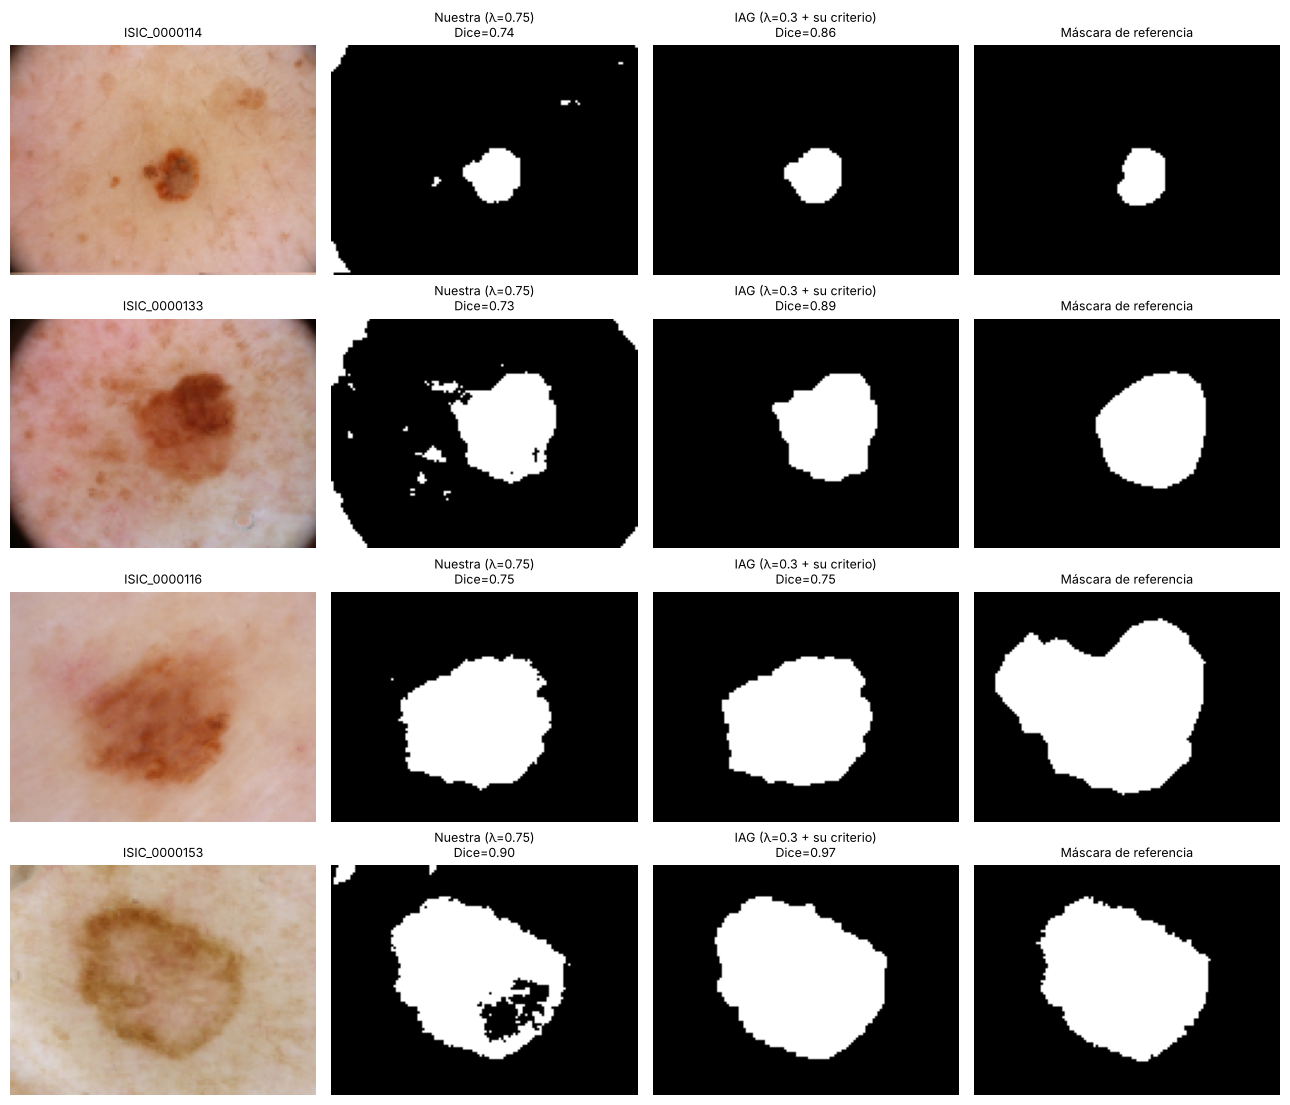

In [34]:
nombres_vis_iag = ['ISIC_0000114', 'ISIC_0000133', 'ISIC_0000116', 'ISIC_0000153']
fig, ax = plt.subplots(len(nombres_vis_iag), 4, figsize=(13, 2.8 * len(nombres_vis_iag)), layout='tight')
for i, nombre in enumerate(nombres_vis_iag):
    idx = nombres_ajuste.index(nombre)
    fila = df_iag.iloc[idx]
    paneles = [(imgs_aj[idx], nombre, None),
               (segs_iag[0.75][idx]['mascara'], f"Nuestra (λ=0.75)\nDice={fila['λ=0.75 + grupo más oscuro (nuestra)']:.2f}", 'gray'),
               (criterio_iag(imgs_aj[idx], segs_iag[LAMBDA_IAG][idx]['etiquetas']),
                f"IAG (λ=0.3 + su criterio)\nDice={fila['λ=0.3 + criterio IAG (recomendación completa)']:.2f}", 'gray'),
               (masks_aj[idx], 'Máscara de referencia', 'gray')]
    for j, (im, titulo, cmap) in enumerate(paneles):
        ax[i, j].imshow(im, cmap=cmap)
        ax[i, j].set_title(titulo, fontsize=9)
        ax[i, j].axis('off')
plt.show()

*Con λ = 0,3 y nuestro criterio, la silueta eligió K = 2 en todas las imágenes, como anticipó la IAG, y el Dice promedio fue de 0,841, prácticamente igual al de solo color (0,842) y menor que el de λ = 0,75 (0,857). En ISIC_0000114 el Dice cae a 0,58 porque con K = 2 la lesión queda en el mismo grupo que las esquinas y las pecas. Es decir, el valor de λ que recomendó la IAG no mejora el método por sí solo.*

*El criterio de la IAG sí mejora el resultado. Con λ = 0,3 el Dice promedio sube a 0,881 y con λ = 0,75 a 0,874. Las mejoras grandes están en las imágenes con falsos positivos, ISIC_0000114 pasa de 0,74 a 0,86 e ISIC_0000133 de 0,73 a 0,89, porque al conservar solo la región conectada más cercana al centro se eliminan las esquinas oscuras y las pecas lejanas. Rellenar los huecos ayuda en ISIC_0000153, que llega a 0,97. En cambio, el criterio no resuelve los bordes claros, ISIC_0000116 e ISIC_0000112 siguen entre 0,75 y 0,78, e ISIC_0000150 baja de 0,81 a 0,78.*

*Aunque la recomendación completa obtuvo un Dice mayor en ajuste, no la adoptamos como configuración final. La razón principal es el protocolo, hicimos la consulta cuando las imágenes de prueba ya se habían evaluado con nuestra configuración, y el criterio de la IAG ataca justamente el fallo que vimos en prueba, el viñeteado de ISIC_0000110. Cambiar la configuración en este punto haría que el resultado de prueba dejara de ser una estimación honesta. Además, la mejora depende de umbrales que la IAG no especificó y que tuvimos que fijar nosotros, y de operaciones de limpieza que no hacen parte de las prácticas del curso. La dejamos como la mejora más clara para una siguiente versión del método, que tendría que evaluarse con imágenes nuevas.*

## 7. Ajuste del método

### 7.1 Cálculo del coeficiente de Dice y del V-measure por configuración

*Para cada combinación e imagen se tomó el K elegido por silueta, se construyó la máscara con el criterio del grupo más oscuro y se calcularon cuatro métricas, considerando la lesión como clase positiva. El Dice se calculó con `f1_score` sobre las máscaras aplanadas, como indica el enunciado, porque equivale al F1-score a nivel de píxel; es la misma métrica usada en el Laboratorio 3 y en las prácticas P7, P9 y P10. La precisión y el recall también vienen de esas prácticas, la precisión dice qué parte de lo que el método marcó como lesión realmente lo es, y el recall qué parte de la lesión real alcanzó a marcar. El V-measure se calculó con `v_measure_score` entre todos los grupos de K-medias y la máscara de referencia. Según la documentación de scikit-learn, es la media armónica entre la homogeneidad y la completitud y no depende de los números de las etiquetas, así que mide si los grupos respetan la división entre lesión y piel sin importar cuál grupo se haya elegido.*

In [35]:
def metricas_mascara(mask_ref, mask_est, etiquetas):
    y_true, y_pred = mask_ref.ravel(), mask_est.ravel()
    return {'dice': f1_score(y_true, y_pred),
            'v_measure': v_measure_score(y_true, etiquetas),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred)}

In [36]:
filas = []
for _, fila in df_sel.iterrows():
    idx = nombres_ajuste.index(fila['imagen'])
    etiq = etiquetas_todas[(fila['beta'], fila['lam'], fila['imagen'])][int(fila['K']) - K_MIN]
    mask_est = construir_mascara(imgs_aj[idx], etiq)
    filas.append({**fila.to_dict(), **metricas_mascara(masks_aj[idx], mask_est, etiq)})

df_ajuste = pd.DataFrame(filas)
df_ajuste.head()

,beta,lam,imagen,K,silueta,configuración,dice,v_measure,precision,recall
0,0,1.0,ISIC_0000085,4,0.414833,"β=0, λ=1 (solo posición)",0.173575,0.007639,0.130945,0.257362
1,0,1.0,ISIC_0000086,4,0.414833,"β=0, λ=1 (solo posición)",0.226707,0.000275,0.219258,0.234680
2,0,1.0,ISIC_0000089,4,0.414833,"β=0, λ=1 (solo posición)",0.188928,0.003645,0.140065,0.290148
3,0,1.0,ISIC_0000094,4,0.414833,"β=0, λ=1 (solo posición)",0.165046,0.013096,0.102147,0.429549
4,0,1.0,ISIC_0000108,4,0.414833,"β=0, λ=1 (solo posición)",0.292400,0.018172,0.254066,0.344356


### 7.2 Tabla comparativa de configuraciones (Dice promedio y V-measure)

*La tabla resume las 10 configuraciones ordenadas por Dice promedio, que es el criterio principal de selección. También muestra la desviación estándar y el peor Dice, para saber si el desempeño es estable entre imágenes, junto con el V-measure, la silueta y el K promedio.*

In [37]:
resumen_config = (df_ajuste.groupby(['configuración', 'beta', 'lam'], sort=False)
                  .agg(dice_promedio=('dice', 'mean'), dice_std=('dice', 'std'), dice_min=('dice', 'min'),
                       v_measure_promedio=('v_measure', 'mean'), silueta_promedio=('silueta', 'mean'),
                       K_promedio=('K', 'mean'))
                  .reset_index()
                  .sort_values('dice_promedio', ascending=False)
                  .reset_index(drop=True))
resumen_config.round(3)

,configuración,beta,lam,dice_promedio,dice_std,dice_min,v_measure_promedio,silueta_promedio,K_promedio
0,"β=1, λ=0.75",1,0.75,0.857,0.076,0.731,0.533,0.480,2.933
1,"β=1, λ=0.5",1,0.50,0.854,0.088,0.670,0.571,0.546,2.600
2,"β=1, λ=0 (solo color)",1,0.00,0.842,0.103,0.582,0.634,0.743,2.000
3,"β=1, λ=0.1",1,0.10,0.842,0.103,0.581,0.634,0.726,2.000
4,"β=1, λ=0.25",1,0.25,0.842,0.103,0.580,0.633,0.672,2.000
5,"β=1, λ=1.5",1,1.50,0.800,0.139,0.442,0.305,0.443,5.133
6,"β=1, λ=2",1,2.00,0.800,0.201,0.142,0.290,0.442,4.933
7,"β=1, λ=1",1,1.00,0.730,0.279,0.000,0.373,0.441,4.667
8,"β=1, λ=4",1,4.00,0.640,0.306,0.056,0.213,0.419,4.733
9,"β=0, λ=1 (solo posición)",0,1.00,0.263,0.107,0.023,0.014,0.414,4.000


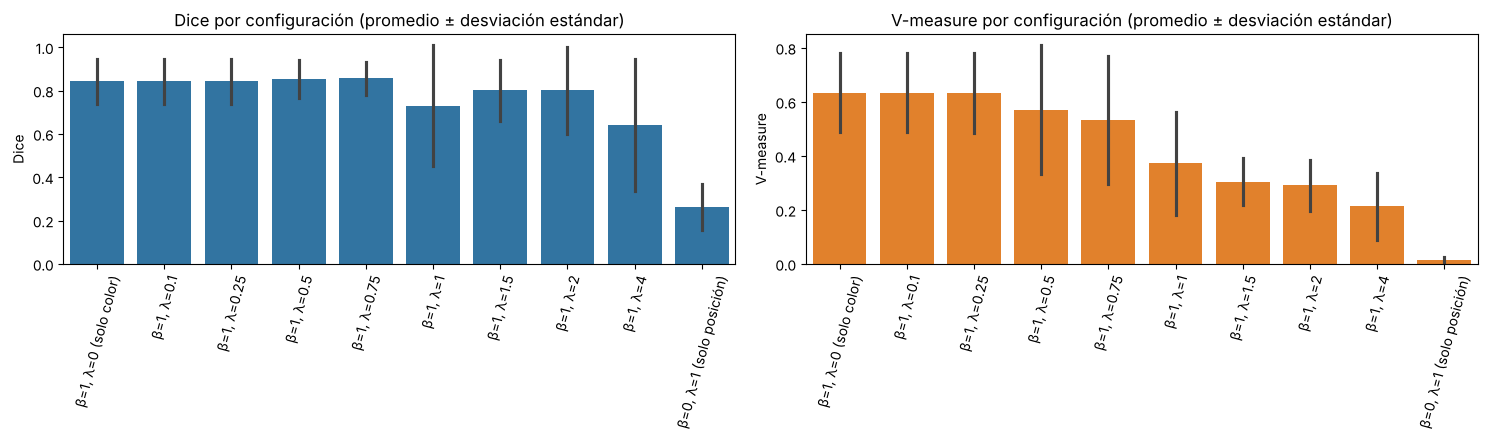

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
orden = [nombre_config(b, l) for b, l in COMBINACIONES]
sns.barplot(data=df_ajuste, x='configuración', y='dice', order=orden, ax=axes[0], errorbar='sd', color='tab:blue')
axes[0].set(title='Dice por configuración (promedio ± desviación estándar)', xlabel='', ylabel='Dice')
sns.barplot(data=df_ajuste, x='configuración', y='v_measure', order=orden, ax=axes[1], errorbar='sd', color='tab:orange')
axes[1].set(title='V-measure por configuración (promedio ± desviación estándar)', xlabel='', ylabel='V-measure')
for ax in axes:
    ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()

*Las dos mejores configuraciones combinan color y posición con una razón λ/β moderada, β = 1, λ = 0,75 obtiene un Dice promedio de 0,857 y β = 1, λ = 0,5 de 0,854. Le siguen las tres configuraciones con poco o ningún peso de posición (λ/β ≤ 0,25), que dan exactamente el mismo Dice de 0,842, porque con un peso tan bajo la posición casi no cambia las distancias y K-medias forma los mismos dos grupos que con solo color. A partir de λ/β = 1 el Dice baja y se vuelve inestable, y la configuración de solo posición es la peor con 0,263, porque sin color los grupos son cuadrantes de la imagen que no tienen relación con la lesión.*

*La diferencia de Dice entre las mejores configuraciones y la de solo color es pequeña (0,015), pero la mejora está en la estabilidad, con λ = 0,75 la desviación estándar baja de 0,103 a 0,076 y el peor caso sube de 0,58 a 0,73. El V-measure no ordena las configuraciones igual que el Dice, el más alto es el de solo color (0,634) y con λ = 0,75 baja a 0,533. Esto pasa porque con más peso de la posición la silueta elige más grupos, y el V-measure castiga que la piel quede repartida en varios grupos aunque la lesión quede bien separada, como advierte la observación del enunciado.*

*Para estudiar la relación entre K, la silueta y el Dice, que se discute en la pregunta 2 del análisis, también se construyó la máscara para todos los K y no solo para el elegido por silueta. Esto usa únicamente las imágenes de ajuste.*

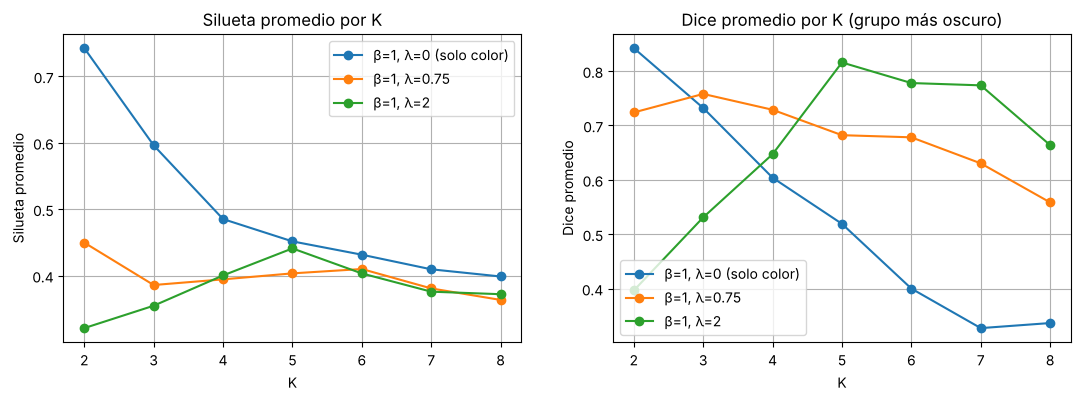

In [39]:
# Dice de cada K (no solo del elegido por silueta), para estudiar la relación entre K, silueta y Dice
filas_kd = []
for _, fila in df_k.iterrows():
    idx = nombres_ajuste.index(fila['imagen'])
    etiq = etiquetas_todas[(fila['beta'], fila['lam'], fila['imagen'])][int(fila['K']) - K_MIN]
    mask_est = construir_mascara(imgs_aj[idx], etiq)
    filas_kd.append({**fila.to_dict(), 'dice': f1_score(masks_aj[idx].ravel(), mask_est.ravel())})
df_kd = pd.DataFrame(filas_kd)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (beta, lam) in [(1, 0), (1, 0.75), (1, 2)]:
    sub = df_kd[(df_kd['beta'] == beta) & (df_kd['lam'] == lam)].groupby('K')[['silueta', 'dice']].mean()
    axes[0].plot(sub.index, sub['silueta'], marker='o', label=nombre_config(beta, lam))
    axes[1].plot(sub.index, sub['dice'], marker='o', label=nombre_config(beta, lam))
axes[0].set(xlabel='K', ylabel='Silueta promedio', title='Silueta promedio por K')
axes[1].set(xlabel='K', ylabel='Dice promedio', title='Dice promedio por K (grupo más oscuro)')
for ax in axes:
    ax.legend()
    ax.grid()
plt.show()

In [40]:
# ¿El K elegido por silueta es el que da el mejor Dice en cada imagen?
idx_mejor_dice = df_kd.groupby(['beta', 'lam', 'imagen'])['dice'].idxmax()
mejor_dice = df_kd.loc[idx_mejor_dice, ['beta', 'lam', 'imagen', 'K', 'dice']].rename(columns={'K': 'K_mejor_dice', 'dice': 'dice_mejor_K'})
comparacion_k = df_ajuste[['beta', 'lam', 'configuración', 'imagen', 'K', 'dice']].merge(mejor_dice, on=['beta', 'lam', 'imagen'])
(comparacion_k.groupby('configuración', sort=False)
 .apply(lambda d: pd.Series({'% imágenes donde coincide K': (d['K'] == d['K_mejor_dice']).mean() * 100,
                             'Dice con K por silueta': d['dice'].mean(),
                             'Dice con el mejor K posible': d['dice_mejor_K'].mean()}))
 .round(3))

,% imágenes donde coincide K,Dice con K por silueta,Dice con el mejor K posible
configuración,,,
"β=0, λ=1 (solo posición)",0.000,0.263,0.637
"β=1, λ=0 (solo color)",86.667,0.842,0.854
"β=1, λ=0.1",86.667,0.842,0.853
"β=1, λ=0.25",86.667,0.842,0.855
"β=1, λ=0.5",80.000,0.854,0.857
"β=1, λ=0.75",33.333,0.857,0.863
"β=1, λ=1",13.333,0.730,0.867
"β=1, λ=1.5",13.333,0.800,0.873
"β=1, λ=2",33.333,0.800,0.838


*Las gráficas muestran que la silueta y el Dice no siempre apuntan al mismo K. Con solo color ambos son máximos en K = 2, y la silueta elige el mejor K en 13 de las 15 imágenes. Con λ = 0,75 la silueta promedio es máxima en K = 2, pero el Dice promedio es máximo en K = 3, y la silueta solo coincide con el mejor K en el 33% de las imágenes. Con λ = 2 la silueta es máxima en K = 5 y el Dice también, pero el Dice cae rápido para K pequeños, porque con tanto peso de la posición los primeros grupos dividen la imagen por zonas y el grupo más oscuro mezcla lesión y piel.*

*La última tabla compara el Dice obtenido con el K de la silueta contra el que se obtendría si se eligiera el mejor K de cada imagen mirando la máscara de referencia. Con λ = 0,75 la diferencia es pequeña (0,857 frente a 0,863), así que la silueta es un buen sustituto para elegir K sin usar las máscaras. Con λ = 1,5 la diferencia es mayor (0,800 frente a 0,873), esa configuración podría ser la mejor si se conociera el K ideal, pero en la práctica la silueta no lo encuentra, y DermAlpes no tendrá máscaras de referencia para elegir K en sus imágenes.*

### 7.3 Revisión de los casos de fallo

*El mapa de calor muestra el Dice de cada imagen en cada configuración, para ver si los fallos se concentran en ciertas imágenes o en ciertas configuraciones. Después se listan las imágenes con menor Dice en la mejor configuración y se comparan sus máscaras estimadas con las de referencia.*

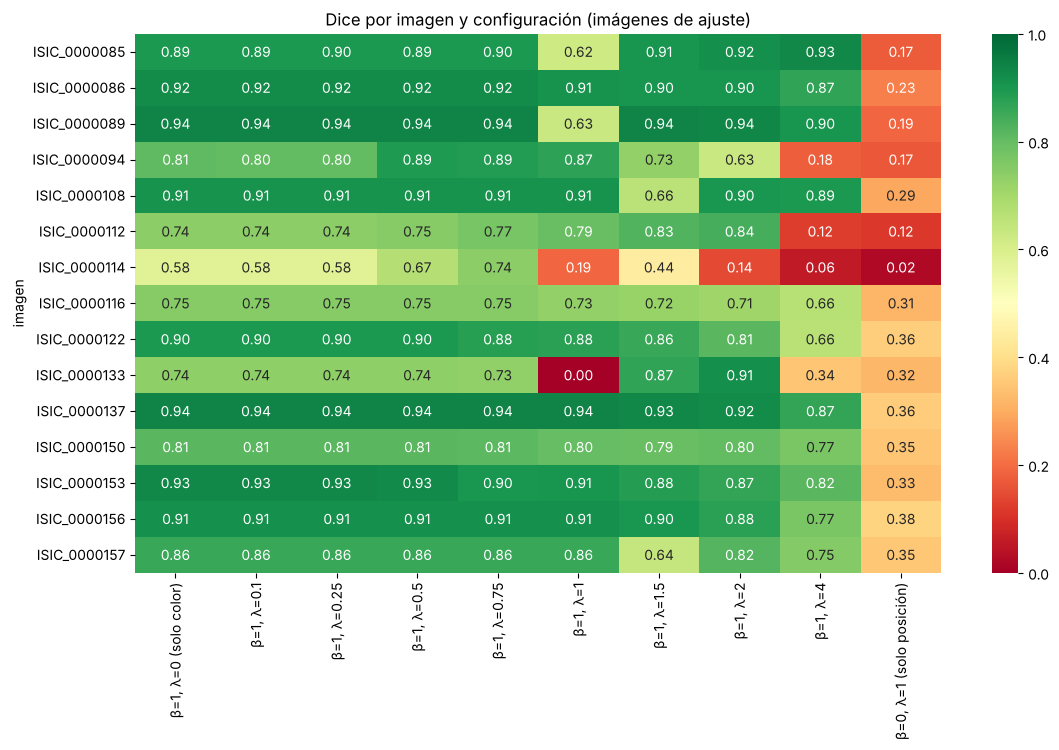

In [41]:
tabla_dice = df_ajuste.pivot_table(index='imagen', columns='configuración', values='dice', sort=False)
tabla_dice = tabla_dice[orden]

plt.figure(figsize=(13, 7))
sns.heatmap(tabla_dice, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1)
plt.title('Dice por imagen y configuración (imágenes de ajuste)')
plt.xlabel('')
plt.show()

In [42]:
mejor = resumen_config.iloc[0]
fallos = df_ajuste[(df_ajuste['beta'] == mejor['beta']) & (df_ajuste['lam'] == mejor['lam'])].sort_values('dice')
fallos[['imagen', 'K', 'silueta', 'dice', 'precision', 'recall', 'v_measure']].round(3).head(6)

,imagen,K,silueta,dice,precision,recall,v_measure
84,ISIC_0000133,2,0.398,0.731,0.669,0.804,0.413
81,ISIC_0000114,5,0.372,0.739,0.645,0.867,0.107
82,ISIC_0000116,2,0.463,0.748,0.998,0.598,0.470
80,ISIC_0000112,5,0.418,0.772,0.952,0.649,0.228
86,ISIC_0000150,2,0.485,0.811,0.999,0.683,0.560
89,ISIC_0000157,2,0.532,0.857,1.000,0.750,0.626


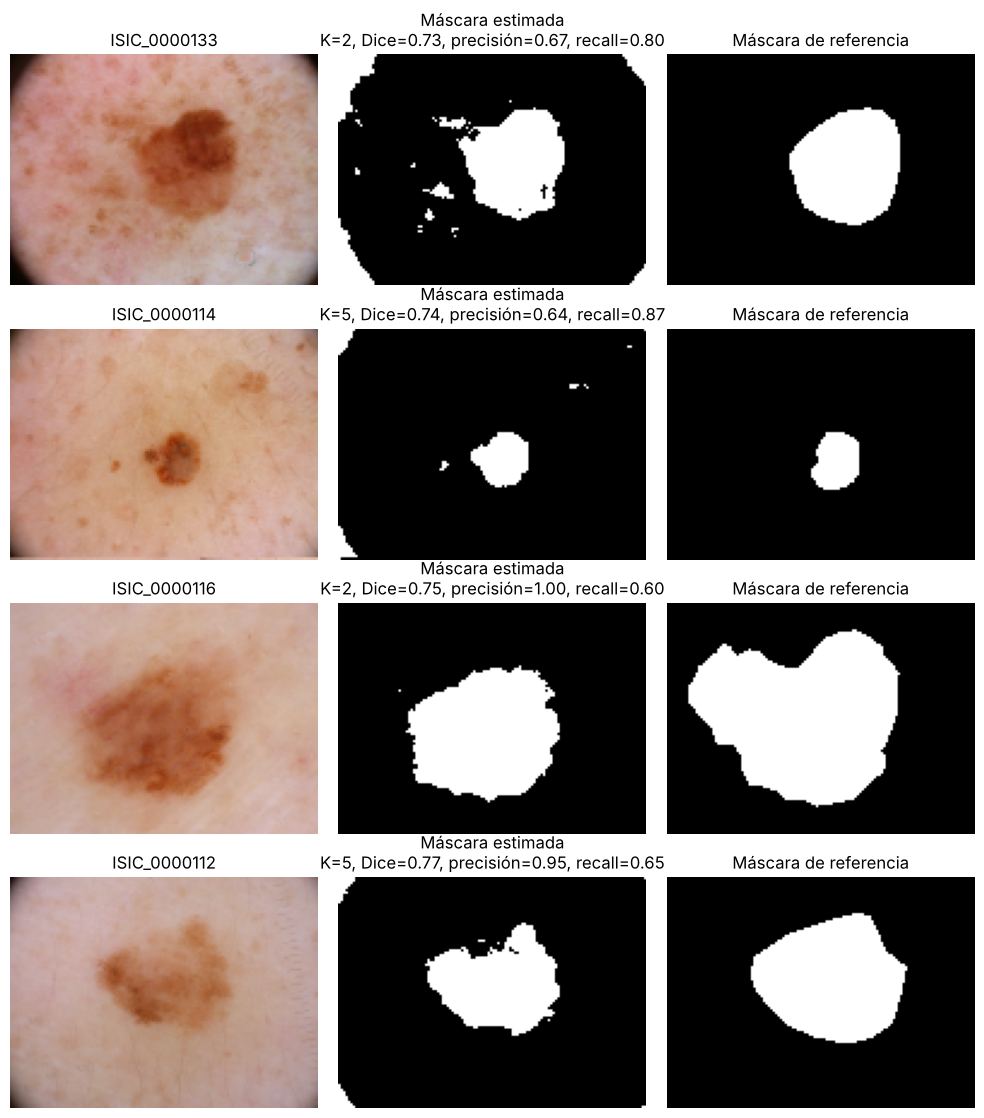

In [43]:
def mostrar_resultados(nombres, imgs, masks_ref, masks_est, info=None):
    fig, ax = plt.subplots(len(nombres), 3, figsize=(10, 2.8 * len(nombres)), layout='tight')
    ax = np.array(ax).reshape(len(nombres), 3)
    for i, nombre in enumerate(nombres):
        ax[i, 0].imshow(imgs[i])
        ax[i, 0].set_title(nombre)
        ax[i, 1].imshow(masks_est[i], cmap='gray')
        ax[i, 1].set_title('Máscara estimada' + (f'\n{info[i]}' if info is not None else ''))
        ax[i, 2].imshow(masks_ref[i], cmap='gray')
        ax[i, 2].set_title('Máscara de referencia')
    for a in ax.flat:
        a.axis('off')
    plt.show()

peores = fallos['imagen'].head(4).tolist()
mostrar_resultados(
    peores,
    [imgs_aj[nombres_ajuste.index(n)] for n in peores],
    [masks_aj[nombres_ajuste.index(n)] for n in peores],
    [construir_mascara(imgs_aj[nombres_ajuste.index(n)],
                       etiquetas_todas[(mejor['beta'], mejor['lam'], n)][int(fallos.set_index('imagen').loc[n, 'K']) - K_MIN])
     for n in peores],
    [f"K={int(r.K)}, Dice={r.dice:.2f}, precisión={r.precision:.2f}, recall={r.recall:.2f}" for r in fallos.head(4).itertuples()])

*Los fallos se concentran en unas pocas imágenes y se repiten en casi todas las configuraciones, así que dependen más de la imagen que de los pesos. En la mejor configuración hay dos tipos de error.*

*El primero son los falsos positivos, es decir, piel marcada como lesión, y se ve en las imágenes con precisión baja. En ISIC_0000133 (Dice 0,73, precisión 0,67) las esquinas negras del viñeteado y varias pecas oscuras quedan en el mismo grupo que la lesión. En ISIC_0000114 (Dice 0,74, precisión 0,65) la lesión es muy pequeña, apenas el 3% de la imagen, así que unas pocas pecas y la esquina oscura pesan mucho en el Dice.*

*El segundo son los falsos negativos, es decir, partes de la lesión que no se marcan, y se ve en las imágenes con recall bajo. En ISIC_0000116 (recall 0,60) e ISIC_0000112 (recall 0,65) la lesión tiene bordes de un café muy claro, casi del color de la piel, que quedan fuera de la máscara aunque la precisión es casi perfecta. Lo mismo pasa en ISIC_0000150 con su zona central grisácea y en ISIC_0000153 con el centro claro, que deja un hueco en la máscara. En todos estos casos la máscara de referencia incluye toda la región de la lesión, mientras que el método solo marca lo que es oscuro.*

### 7.4 Visualización de los grupos: dos configuraciones con mayor Dice, solo color y solo posición

*Como pide el enunciado, se visualizaron la imagen original y los grupos obtenidos en las dos configuraciones con mayor Dice promedio, la de solo color y la de solo posición. Se tomó la idea de la práctica P13 de pintar cada píxel con el color de su grupo. En P13 se usaba el centroide, pero aquí el centroide está en el espacio normalizado y multiplicado por los pesos, y con β = 0 no tiene información de color. Por eso cada grupo se pinta con el color promedio original de sus píxeles. Se escogieron cinco imágenes, una que funciona bien (ISIC_0000085) y cuatro con los problemas descritos en la sección 7.3.*

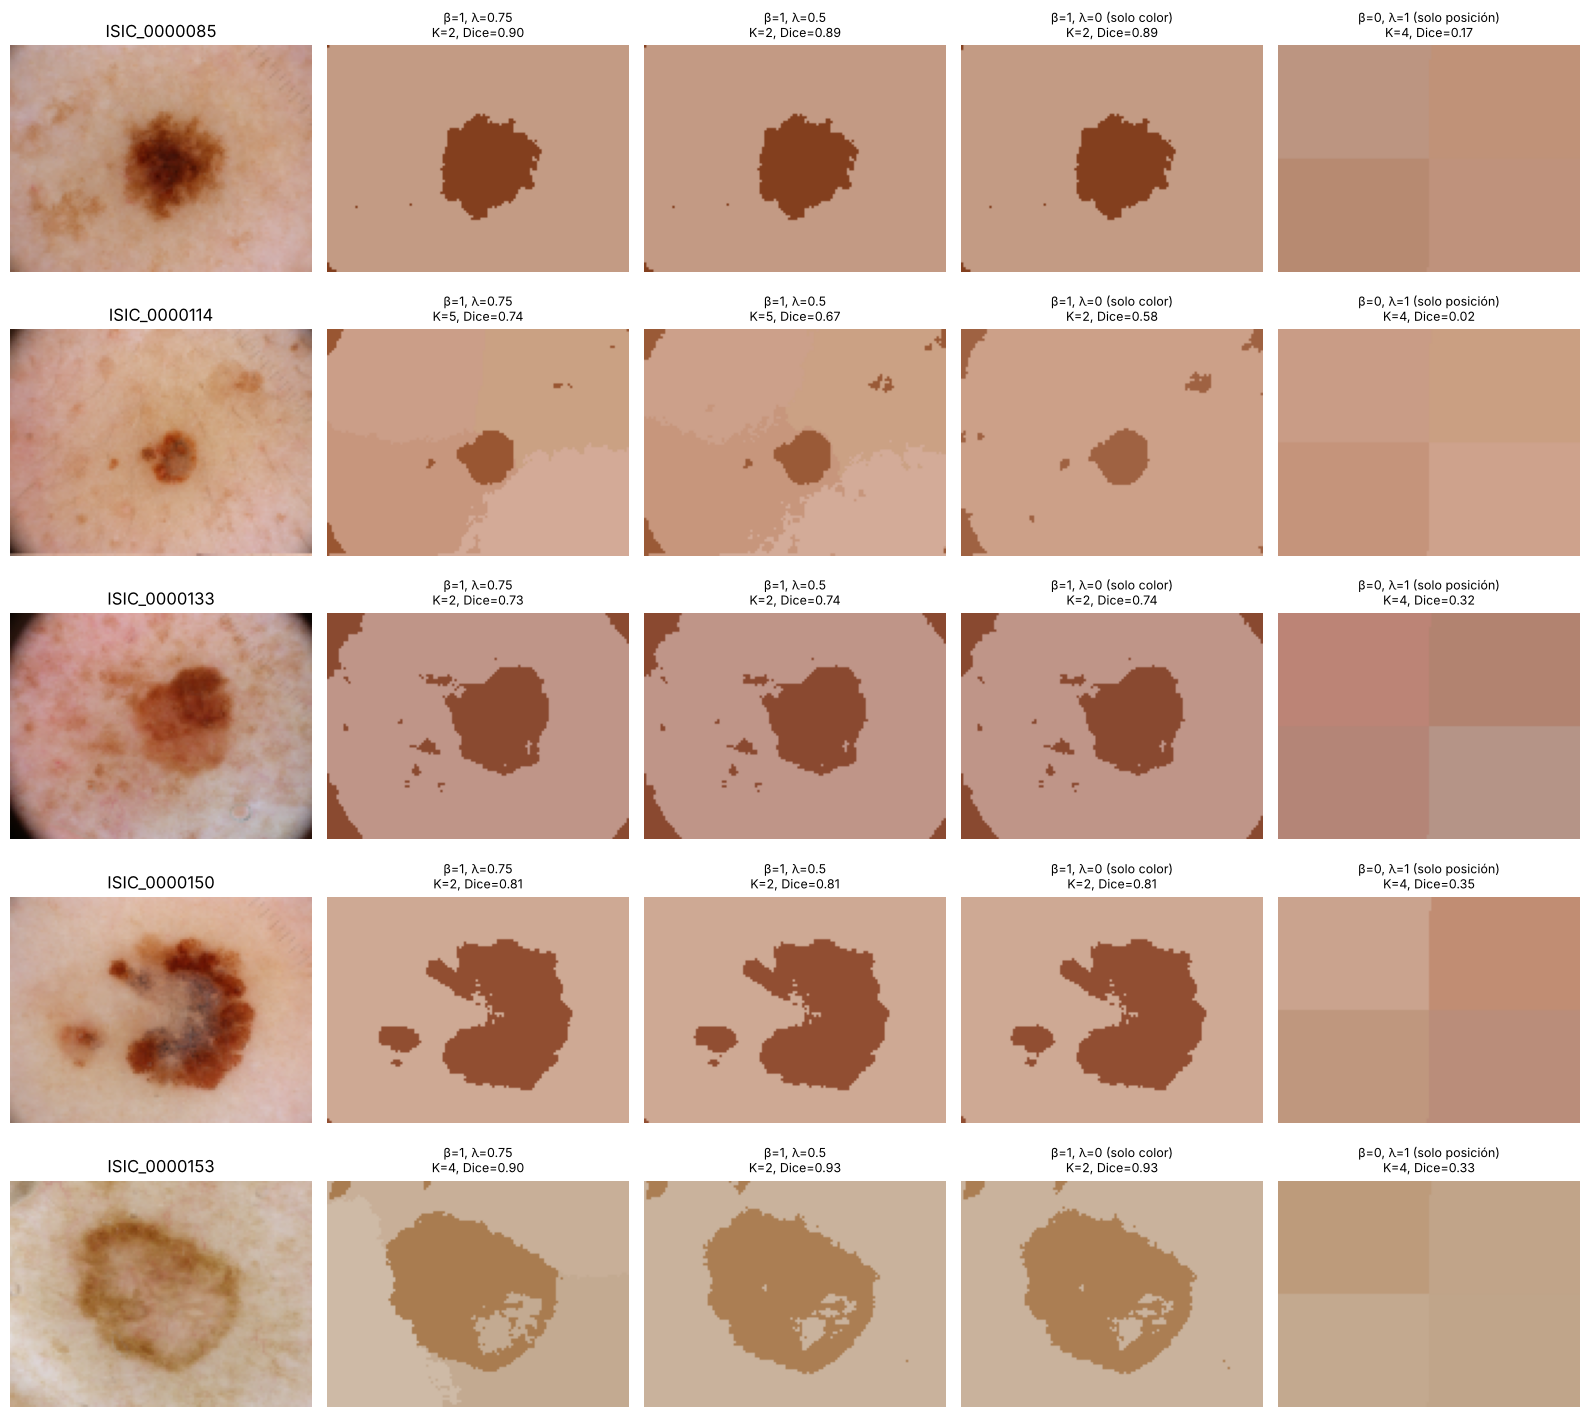

In [44]:
def imagen_segmentada(img, etiquetas):
    # Como en la práctica P13, cada píxel toma el color de su grupo; aquí se usa el color promedio
    # original de los píxeles del grupo, porque con β = 0 los centroides no tienen información de color
    X = img.reshape((-1, 3)).astype(float)
    colores = np.array([X[etiquetas == g].mean(axis=0) for g in range(etiquetas.max() + 1)])
    return colores[etiquetas].reshape(img.shape).astype(np.uint8)

configs_vis = [(resumen_config.loc[0, 'beta'], resumen_config.loc[0, 'lam']),
               (resumen_config.loc[1, 'beta'], resumen_config.loc[1, 'lam']),
               (1, 0), (0, 1)]
imagenes_vis = ['ISIC_0000085', 'ISIC_0000114', 'ISIC_0000133', 'ISIC_0000150', 'ISIC_0000153']

fig, ax = plt.subplots(len(imagenes_vis), len(configs_vis) + 1, figsize=(16, 2.9 * len(imagenes_vis)), layout='tight')
for i, nombre in enumerate(imagenes_vis):
    idx = nombres_ajuste.index(nombre)
    ax[i, 0].imshow(imgs_aj[idx])
    ax[i, 0].set_title(nombre)
    for j, (beta, lam) in enumerate(configs_vis):
        fila = df_ajuste[(df_ajuste['beta'] == beta) & (df_ajuste['lam'] == lam) & (df_ajuste['imagen'] == nombre)].iloc[0]
        etiq = etiquetas_todas[(beta, lam, nombre)][int(fila['K']) - K_MIN]
        ax[i, j + 1].imshow(imagen_segmentada(imgs_aj[idx], etiq))
        ax[i, j + 1].set_title(f"{nombre_config(beta, lam)}\nK={int(fila['K'])}, Dice={fila['dice']:.2f}", fontsize=9)
for a in ax.flat:
    a.axis('off')
plt.show()

*En ISIC_0000085, una lesión oscura sobre piel clara, las tres configuraciones con color dan casi el mismo resultado con K = 2, un grupo para la lesión y otro para la piel. La configuración de solo posición divide todas las imágenes en cuatro rectángulos iguales sin relación con la lesión, lo que confirma que la posición por sí sola no sirve para segmentar.*

*La posición ayuda en ISIC_0000114. Con solo color, K = 2 y el grupo oscuro incluye la lesión, una mancha arriba a la derecha y las esquinas, con un Dice de 0,58. Con λ = 0,75 la silueta elige K = 5 y la imagen se divide en zonas; la lesión queda en un grupo propio porque es oscura y compacta, mientras que las manchas lejanas quedan en otros grupos. El Dice sube a 0,74. La posición no ayuda en ISIC_0000133 ni en ISIC_0000150, las esquinas oscuras de la primera y la mancha satélite de la segunda quedan en el grupo de la lesión con cualquier peso, porque su color es muy parecido. En ISIC_0000153, con λ = 0,75 la silueta elige K = 4 y la piel del lado izquierdo se separa en otro grupo; la lesión se mantiene, pero el hueco del centro claro sigue ahí y el Dice baja un poco frente a K = 2 (0,90 frente a 0,93).*

### 7.5 Selección y justificación de la configuración final (β, λ y criterio)

*La configuración final es β = 1, λ = 0,75, con K elegido por silueta entre 2 y 8 en cada imagen y el criterio del grupo más oscuro para construir la máscara. Se eligió por tener el mayor Dice promedio en las imágenes de ajuste (0,857), que es el criterio principal del enunciado. La diferencia con β = 1, λ = 0,5 (0,854) es muy pequeña, pero λ = 0,75 también es la más estable, tiene la menor desviación estándar (0,076) y el mejor peor caso (0,731), lo que para DermAlpes significa menos imágenes con una segmentación mala. Su V-measure (0,533) es menor que el de solo color, pero como se explicó en la sección 7.2, eso se debe a que la piel queda repartida en varios grupos y no afecta la máscara de la lesión.*

*Frente a usar solo color, incluir la posición ayuda en las imágenes con manchas o pecas lejos de la lesión, como ISIC_0000114 e ISIC_0000094, y no empeora de forma importante ninguna otra. La recomendación de la IAG, que se probó en la sección 6.3, no se adoptó por las razones explicadas allí. Desde este punto la configuración queda fija y se aplica sin cambios a las imágenes de prueba.*

In [45]:
CONFIG_FINAL = {'beta': float(resumen_config.loc[0, 'beta']),
                'lam': float(resumen_config.loc[0, 'lam']),
                'criterio': 'grupo más oscuro (menor brillo promedio en RGB)',
                'K': f'seleccionado por silueta entre {K_MIN} y {K_MAX} en cada imagen'}
CONFIG_FINAL

{'beta': 1.0,
 'lam': 0.75,
 'criterio': 'grupo más oscuro (menor brillo promedio en RGB)',
 'K': 'seleccionado por silueta entre 2 y 8 en cada imagen'}

In [46]:
dice_ajuste_final = df_ajuste[(df_ajuste['beta'] == CONFIG_FINAL['beta']) & (df_ajuste['lam'] == CONFIG_FINAL['lam'])]
print(f"Dice promedio en ajuste con la configuración final: {dice_ajuste_final['dice'].mean():.3f}")

Dice promedio en ajuste con la configuración final: 0.857


## 8. Evaluación en las imágenes de prueba

### 8.1 Aplicación de la configuración final sin modificaciones

*Las imágenes de prueba se cargan y preparan con las mismas funciones de las secciones 0.3 y 3, y se les aplica la función `segmentar` con la configuración final, sin ningún cambio.*

In [47]:
img_paths_prueba = sorted(glob(os.path.join('.', 'data', 'prueba', 'imagenes', '*.jpg')))
mask_paths_prueba = sorted(glob(os.path.join('.', 'data', 'prueba', 'mascaras', '*.png')))

imgs_prueba = load_imgs(img_paths_prueba)
masks_prueba = load_masks(mask_paths_prueba)
nombres_prueba = [os.path.basename(p).replace('.jpg', '') for p in img_paths_prueba]
print("Prueba coincide con el enunciado:", sorted(IDS_PRUEBA) == nombres_prueba)

imgs_pr = [reducir_imagen(img) for img in imgs_prueba]
masks_pr = [preparar_mascara(m) for m in masks_prueba]

Prueba coincide con el enunciado: True


In [48]:
resultados_prueba = [segmentar(img, CONFIG_FINAL['beta'], CONFIG_FINAL['lam']) for img in imgs_pr]

### 8.2 Tabla de resultados por imagen (K, silueta, Dice, V-measure, precisión y recall)

*La tabla muestra, para cada imagen de prueba, el K elegido por silueta, la silueta, el Dice, el V-measure, la precisión y el recall, considerando la lesión como clase positiva.*

In [49]:
filas_pr = []
for nombre, r, mask in zip(nombres_prueba, resultados_prueba, masks_pr):
    filas_pr.append({'imagen': nombre, 'K': r['K'], 'silueta': r['silueta'],
                     **metricas_mascara(mask, r['mascara'], r['etiquetas'])})
df_prueba = pd.DataFrame(filas_pr)
df_prueba.loc['Promedio'] = df_prueba.drop(columns='imagen').mean()
df_prueba.loc['Promedio', 'imagen'] = 'Promedio'
df_prueba.round(3)

,imagen,K,silueta,dice,v_measure,precision,recall
0,ISIC_0000087,2.0,0.490,0.874,0.622,0.995,0.779
1,ISIC_0000105,5.0,0.405,0.883,0.209,0.942,0.831
2,ISIC_0000110,6.0,0.400,0.000,0.197,0.000,0.000
3,ISIC_0000123,2.0,0.502,0.914,0.732,0.867,0.966
4,ISIC_0000128,2.0,0.553,0.930,0.811,0.999,0.870
Promedio,Promedio,3.4,0.470,0.720,0.514,0.761,0.689


### 8.3 Imagen original, máscara estimada y máscara de referencia

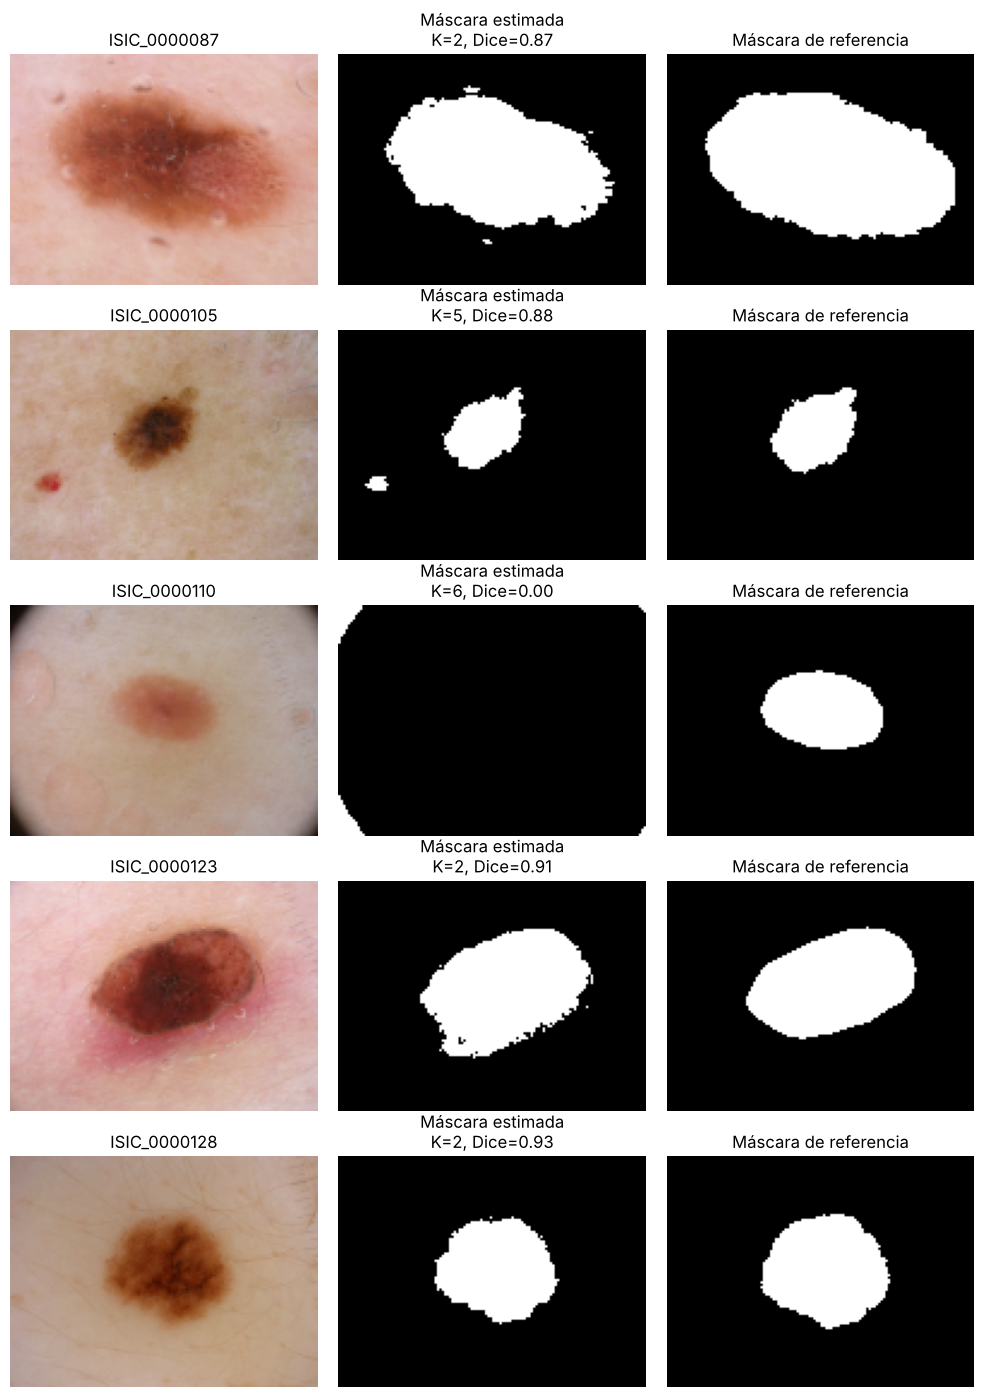

In [50]:
mostrar_resultados(nombres_prueba, imgs_pr, masks_pr, [r['mascara'] for r in resultados_prueba],
                   [f"K={r['K']}, Dice={d:.2f}" for r, d in zip(resultados_prueba, df_prueba['dice'])])

*En cuatro de las cinco imágenes la máscara estimada coincide bien con la de referencia, con Dice entre 0,87 y 0,93. En ISIC_0000087 la máscara deja por fuera parte del borde de la lesión, que es de un café más claro (recall 0,78). En ISIC_0000105 la lesión queda bien delimitada, pero también se marca un pequeño punto rojo en la esquina inferior izquierda. En ISIC_0000123 la máscara cubre casi toda la lesión, aunque incluye un poco de la piel enrojecida alrededor.*

*ISIC_0000110 es un fallo total, con Dice de 0. La foto tiene un viñeteado negro muy marcado en todo el borde y la lesión es de un rosado claro. El grupo más oscuro es el borde negro, así que la máscara marca el borde y nada de la lesión.*

### 8.4 Comparación del Dice promedio de ajuste y prueba

In [51]:
comparacion = pd.DataFrame({
    'Ajuste (15 imágenes)': dice_ajuste_final[['dice', 'v_measure', 'precision', 'recall', 'silueta', 'K']].mean(),
    'Prueba (5 imágenes)': df_prueba.drop(index='Promedio')[['dice', 'v_measure', 'precision', 'recall', 'silueta', 'K']].astype(float).mean()
})
comparacion.round(3)

,Ajuste (15 imágenes),Prueba (5 imágenes)
dice,0.857,0.720
v_measure,0.533,0.514
precision,0.930,0.761
recall,0.809,0.689
silueta,0.480,0.470
K,2.933,3.400


*El Dice promedio baja de 0,857 en ajuste a 0,720 en prueba. Esta caída se explica casi por completo por ISIC_0000110, sin ella, el Dice promedio de las otras cuatro imágenes de prueba es 0,90, incluso mayor que el de ajuste. La silueta y el K promedio son parecidos en los dos conjuntos, así que el método se comporta igual en ambos; lo que cambia es que en prueba apareció un caso en el que el criterio del grupo más oscuro no aplica. Con solo cinco imágenes, una sola imagen mueve el promedio 18 puntos, así que esta estimación es muy incierta.*

### 8.5 Principales aciertos y errores

*El principal acierto es que el método delimita bien las lesiones cafés u oscuras sobre piel clara, que son la mayoría del conjunto. En ese tipo de imágenes la precisión es muy alta (entre 0,87 y 1,0), es decir, lo que el método marca como lesión casi siempre lo es. Esto también se vio en ajuste, donde la precisión promedio fue de 0,93.*

*Hay dos errores principales, los mismos que se vieron en ajuste. El primero es que el recall es más bajo que la precisión (0,81 en ajuste), el método suele quedarse corto en los bordes claros de la lesión, porque solo marca la parte más oscura. Para DermAlpes esto significa que la lesión se vería más pequeña de lo que es. El segundo es que el criterio falla cuando hay algo más oscuro que la lesión, como el viñeteado de ISIC_0000110 o, en menor medida, el punto rojo de ISIC_0000105. En ajuste ya se había visto este problema en ISIC_0000133, pero ahí la lesión era más oscura que el viñeteado y solo se agregaron las esquinas; en ISIC_0000110 la lesión es tan clara que el método la pierde por completo. Como dice el enunciado, no se espera un Dice alto en todas las imágenes, este resultado muestra el límite de un método que solo usa color y posición.*

## 9. Análisis de resultados

#### 9.1 ¿Qué efecto tuvo incluir la posición de los píxeles? Expliquen en qué imágenes mejoró o perjudicó la segmentación y por qué.

*β y λ ponderan el color y la posición de cada píxel antes de K-medias. Con λ = 0 solo importa el color, así que una peca oscura en la esquina se parece a la lesión y queda en su mismo grupo. Al darle algo de peso a la posición (λ = 0,75), esa peca queda lejos de la lesión y puede formar su propio grupo.*

*Esto mejoró las imágenes con manchas lejos de la lesión, en ISIC_0000114 el Dice pasó de 0,58 a 0,74 y en ISIC_0000094 de 0,81 a 0,89. En promedio la mejora fue pequeña (de 0,842 a 0,857), pero el peor caso subió de 0,58 a 0,73. La posición perjudicó cuando pesó demasiado, con λ ≥ 1 K-medias empieza a partir la foto en zonas sin mirar el color, y con solo posición los grupos son cuatro rectángulos que no tienen nada que ver con la lesión (Dice 0,26). También empeoró un poco ISIC_0000153 (de 0,93 a 0,90), donde la imagen se dividió en zonas. Para DermAlpes, la posición sirve como complemento del color, pero no lo reemplaza.*

#### 9.2 ¿Qué relación encontraron entre K, la silueta y el Dice? ¿Por qué estas métricas no necesariamente conducen a las mismas decisiones?

*K es el único hiperparámetro de K-medias, y lo elegimos con la silueta, que mide qué tan separados quedan los grupos. El Dice mide otra cosa, si la máscara coincide con la del dermatólogo. Con solo color las dos métricas casi siempre coinciden y ambas prefieren K = 2. Con λ = 0,75 la silueta prefiere K = 2 y el Dice K = 3, pero la diferencia es pequeña, 0,857 con el K de la silueta contra 0,863 si se eligiera el mejor K de cada imagen.*

*No llevan a la misma decisión porque K-medias no sabe qué es piel ni qué es lesión. La silueta puede premiar grupos muy ordenados, por ejemplo piel clara y piel rosada, aunque la lesión quede mezclada con otra cosa. Aun así usamos la silueta porque no necesita la máscara del dermatólogo, y DermAlpes no tendrá esas máscaras para sus pacientes.*

#### 9.3 ¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué es importante no modificar el método después de consultar las máscaras de prueba?

*En ajuste el Dice promedio fue 0,857 y en prueba 0,720. La caída se debe casi toda a una imagen, ISIC_0000110, con Dice 0, la foto tiene un borde negro más oscuro que la lesión, y el criterio del grupo más oscuro escogió el borde. Sin esa imagen, la prueba da 0,90. Con solo cinco imágenes de prueba, una sola cambia mucho el promedio.*

*No cambiamos el método después de ver la prueba porque entonces el 0,720 dejaría de ser honesto, estaríamos ajustando el método a esas cinco imágenes, como usar el conjunto de test para elegir hiperparámetros. Para DermAlpes eso daría una idea demasiado optimista de cómo funcionará con fotos nuevas.*

#### 9.4 Identifiquen dos limitaciones de su modelo y expliquen sus posibles causas a partir de las imágenes y de la representación RGB + posición.

*La primera limitación es que el criterio supone que la lesión es lo más oscuro de la foto. K-medias agrupa bien por color, pero si hay algo más oscuro que la lesión, como el borde negro del dermatoscopio en ISIC_0000110 o las esquinas de ISIC_0000133, ese es el grupo que se marca como lesión. La causa es que la representación solo tiene color y posición, no sabe de forma ni de textura, y no sabe que el borde de la foto no es piel.*

*La segunda es que las lesiones con bordes claros o centros claros quedan incompletas (ISIC_0000116, ISIC_0000112, ISIC_0000150 e ISIC_0000153). Esas zonas tienen un color parecido al de la piel, así que K-medias las junta con ella, y como solo marcamos el grupo más oscuro, la máscara queda más pequeña que la lesión real. Además, `MinMaxScaler` normaliza cada foto con su propio mínimo y máximo, así que el mismo λ no pesa exactamente igual en todas las imágenes.*

#### 9.5 En el contexto de DermAlpes, ¿qué consecuencias podrían tener los falsos positivos y falsos negativos? ¿Qué sesgos y problemas de generalización deben considerarse antes de utilizar el método con nuevas poblaciones o condiciones de adquisición?

*Un falso positivo es piel marcada como lesión y un falso negativo es lesión que no se marca. Para DermAlpes los falsos negativos son los más preocupantes, nuestro método suele quedarse corto en los bordes claros, así que la lesión se vería más pequeña y más regular de lo que es, y el dermatólogo podría subestimar el riesgo. Los falsos positivos, como marcar pecas o esquinas oscuras, hacen que la lesión parezca más grande o con una forma extraña y le hacen perder tiempo al especialista. Por eso la máscara siempre debe mostrarse sobre la foto original y el dermatólogo debe poder corregirla.*

*Sobre sesgos y generalización, el método se ajustó con solo 15 imágenes, casi todas de piel clara con lesiones oscuras. Como el criterio depende del contraste entre lesión y piel, en pieles más oscuras podría fallar mucho más. También importan las condiciones de las fotos, otros dermatoscopios, otra luz o más viñeteado, que ya vimos que basta para que el método falle. Antes de usarlo con pacientes, DermAlpes debería probarlo con fotos de sus propios centros de salud y con personas de distintos tonos de piel.*

## 10. Uso de herramientas de IA generativa

### 10.1 Declaración del uso (herramienta y tipo de uso)

**Herramienta utilizada:** *Claude (Anthropic).* **Tipos de uso:**

- ***Generación de la estructura del notebook.*** *A partir del enunciado del laboratorio y de la estructura de los laboratorios y prácticas anteriores del curso, se generó el esqueleto de secciones y subsecciones que organiza este documento y la celda de importación de librerías.*
- ***Preparación del conjunto de datos.*** *Se filtraron las 20 imágenes indicadas en el enunciado (15 de ajuste y 5 de prueba) a partir de la descarga de ISIC 2016, se descargaron sus máscaras de referencia y se organizaron en las carpetas `data/ajuste` y `data/prueba`.*


### 10.2 Prompts utilizados

*Se registraron los prompts principales utilizados durante el trabajo, en orden cronológico:*

- *"Vamos a empezar a hacer mi laboratorio 4 de MACHINE, primero que todo necesito que, dentro de la carpeta LABORATORIO 4 vamos a generar el md, basandote en mis laboratorios y practicas. solo pon los titulos y subtitulos que tenga que tener mi laboratorio (tambien las importaciones iniciales). adicionalmente, en la parte de declaracion de IA ( al final) declara este prompt. si tienes mas preguntas hazmelas antes de empezar. Tambien ya descargue el conjunto de datos de ISIC, pero porfavor solo deja el set que necesito (especificado en el md que te estoy pasando como input)."* (adjuntando el enunciado del Laboratorio 4).
- *"las indicaciones del laboratorio si me permiten organizar asi la carpeta data ?"* (consulta sobre si el enunciado permite organizar la carpeta `data` en las subcarpetas `ajuste` y `prueba`).
- *"agrega el prompt anterior a la declaracion de IA y al principio del md expliquemos en un apartado de md como organizamos la carpeta data"*


### 10.3 Análisis crítico del resultado (responder al menos dos de las siguientes preguntas)

***¿Qué partes del contenido generado fueron correctas y útiles?*** *La estructura del notebook fue un buen punto de partida, porque sigue el mismo orden de las actividades y las preguntas del enunciado y la misma organización de los laboratorios anteriores, de modo que ninguna actividad quedó sin su sección. También fue útil la preparación de los datos, porque al filtrar las 20 imágenes del enunciado la herramienta detectó que la descarga que teníamos no incluía las máscaras de referencia, que son necesarias para calcular el Dice y el V-measure, y las descargó del archivo oficial del reto. Por último, la respuesta sobre la organización de la carpeta `data` aclaró que el enunciado no exige una estructura específica, y que separar las imágenes de ajuste y de prueba en carpetas distintas ayuda a cumplir la condición del protocolo, siempre que se explique en el notebook cómo están organizados los datos.*

***¿Qué errores, imprecisiones o limitaciones se identificaron?*** *Al generar la celda de importaciones, la herramienta indicó que todas las librerías, excepto las de los bonos y el V-measure, venían de las prácticas del curso, pero al revisar el código de las prácticas se encontró que `PCA` tampoco se usa en ninguna, así que esa afirmación no era correcta. Además, la estructura propuesta fue solo una guía inicial, porque varias secciones se ajustaron a medida que avanzamos en el laboratorio, por ejemplo el criterio de la máscara, que pasó de dos criterios a uno, y el apartado del video, que se retiró del notebook.*

### 10.4 Aportes propios de los estudiantes

***¿Qué fue desarrollado, modificado o decidido por los estudiantes? ¿Qué ajustes se realizaron sobre el código o la explicación original?*** *Se decidió organizar los datos en carpetas separadas de ajuste y prueba, reducir las imágenes a 128 píxeles de ancho, normalizar con `MinMaxScaler` igual que en la práctica P11, usar un solo criterio para construir la máscara (el grupo más oscuro) y elegir la configuración final por el Dice promedio en las imágenes de ajuste. También se decidió mantener nuestra configuración aunque la recomendación de la IAG obtuvo un Dice mayor en ajuste, porque las imágenes de prueba ya se habían evaluado. El código de las prácticas P11 y P13 se adaptó al caso, `show_imgs` se modificó para mostrar un número impar de imágenes, `evaluar_k` se cambió para calcular la silueta sobre una muestra de píxeles y devolver las etiquetas de cada K, y la representación de P13 se amplió para multiplicar el color por β y la posición por λ.*

***¿Qué aprendizajes se obtuvieron del proceso?*** *Que en un problema sin etiquetas la métrica que se usa para elegir K, la silueta, no siempre coincide con la que mide el objetivo del caso, el Dice, porque K-medias no sabe qué es lesión y qué es piel. También que β y λ no son parámetros de K-medias, sino pesos que deciden cuánto importan el color y la posición antes de agrupar, y que darle un poco de peso a la posición ayuda a separar las pecas lejanas, pero si pesa demasiado la imagen se parte en zonas sin relación con la lesión. Por último, que separar las imágenes de ajuste de las de prueba fue lo que permitió ver el fallo de ISIC_0000110, que no habríamos detectado evaluando con las mismas imágenes con las que se ajustó el método.*

### 10.5 Actividad de verificación: ¿la recomendación funcionó en nuestras imágenes? ¿En qué acertó y en qué falló? ¿Por qué la IAG no podía anticipar el comportamiento del método en nuestras imágenes?

***¿La recomendación funcionó en nuestras imágenes?*** *En parte, ya q el valor de λ que recomendó (0,3) no funcionó mejor que el nuestro, con nuestro criterio dio un Dice de 0,841, frente a 0,857 con λ = 0,75, porque la silueta elige K = 2 en todas las imágenes y la posición pesa muy poco para separar las manchas lejanas. Su criterio para construir la máscara sí funcionó, subió el Dice promedio en ajuste a 0,881 y el peor caso de 0,73 a 0,75 (sección 6.3).*

***¿En qué acertó y en qué falló?*** *Acertó en varios puntos, el orden entre escalar y aplicar los pesos, que nuestro pipeline ya cumplía; que la silueta tiende a elegir K = 2; que con K = 2 la lesión se mezcla con el viñeteado; que los bordes claros quedan con la piel, y que los falsos positivos del viñeteado son lo que más baja el Dice. Falló en el valor de λ, en nuestras imágenes λ = 0,3 se comporta igual que usar solo color, y el mejor resultado con nuestro criterio estuvo en λ = 0,75. Además, su criterio no resolvió los bordes claros (ISIC_0000116 e ISIC_0000112 siguen cerca de 0,75) y dejó varios umbrales sin un valor concreto, que tuvimos que fijar nosotros.*

***¿Por qué la IAG no podía anticipar el comportamiento del método en nuestras imágenes?*** *Porque no vio las imágenes ni las máscaras, solo una descripción general. No podía saber qué tan oscuras son las esquinas en cada foto, qué tan parecidos son los bordes claros a la piel ni cómo estira `MinMaxScaler` el color en cada imagen, y todo eso cambia qué razón λ/β funciona mejor y qué K elige la silueta. Sus recomendaciones se basan en lo que suele pasar en este tipo de problemas, lo que es útil como punto de partida, pero solo al probarlas con nuestros datos pudimos saber cuáles funcionaban. Por eso no se deben aceptar sus valores sin verificarlos, la IAG tampoco tiene forma de saber si su propuesta funcionaría con las imágenes de prueba.*

## 11. Referencias

**Fuente de datos**

- *Gutman, D., Codella, N. C. F., Celebi, E., Helba, B., Marchetti, M., Mishra, N. y Halpern, A. (2016). Skin Lesion Analysis toward Melanoma Detection: A Challenge at the International Symposium on Biomedical Imaging (ISBI) 2016, hosted by the International Skin Imaging Collaboration (ISIC). arXiv:1605.01397. Datos: ISIC 2016, tarea de segmentación de lesiones (`ISBI2016_ISIC_Part1_Training_Data` y `ISBI2016_ISIC_Part1_Training_GroundTruth`). https://challenge.isic-archive.com/landing/2016/37/*

**Material del curso**

- *Práctica P11: Agrupación con K-means. De ahí provienen el pipeline, `MinMaxScaler`, los parámetros de `KMeans` y la función `evaluar_k` para seleccionar K con el coeficiente de la silueta.*
- *Práctica P13: Segmentación de imágenes con K-Means. De ahí provienen `load_imgs`, `show_imgs`, `get_img_masks`, la construcción de las coordenadas con `np.meshgrid`, la idea de pintar cada píxel con el color de su grupo y el muestreo de píxeles de `plot_data`.*
- *Prácticas P7, P9 y P10: uso de `f1_score`, `precision_score` y `recall_score`. Prácticas P3 y P8: gráficas con `seaborn`.*
- *Valbuena, L. y Goyeneche, J. (2026). Laboratorio 3: La tarea de clasificación. Curso ISIS-2611. De ahí provienen la estructura del notebook y el uso de `FunctionTransformer` dentro del pipeline.*

**Documentación oficial**

- *scikit-learn. `silhouette_score` (parámetros `sample_size` y `random_state`): https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html*
- *scikit-learn. `v_measure_score`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.v_measure_score.html*
- *scikit-learn. `PCA`: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html*
- *scikit-learn. `TSNE`: https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html*
- *scikit-learn. `MeanShift`: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MeanShift.html*
- *scikit-learn. `estimate_bandwidth`: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.estimate_bandwidth.html*
- *scikit-learn. A demo of the mean-shift clustering algorithm: https://scikit-learn.org/stable/auto_examples/cluster/plot_mean_shift.html*
- *OpenCV. Geometric Image Transformations, `resize` (`INTER_AREA` e `INTER_NEAREST`): https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html*
- *OpenCV. Image file reading and writing, `imread` (`IMREAD_GRAYSCALE`): https://docs.opencv.org/4.x/d4/da8/group__imgcodecs.html*
- *Python. Módulo `time`: https://docs.python.org/3/library/time.html*
- *OpenCV. Morphological Transformations (`morphologyEx`, apertura y cierre): https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html*
- *OpenCV. Structural Analysis and Shape Descriptors (`connectedComponentsWithStats`): https://docs.opencv.org/4.x/d3/dc0/group__imgproc__shape.html*
- *SciPy. `scipy.ndimage.binary_fill_holes`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.binary_fill_holes.html*

## 12. Bonos

### 12.1 Bono A. Visualización del espacio de representación (PCA o t-SNE)

*Se tomó ISIC_0000153, una lesión con el centro claro, y una muestra de 2.000 de sus píxeles con la representación de la configuración final. La muestra se sacó con `np.random.choice`, como en `plot_data` de la práctica P13. Sobre esa muestra se aplicaron PCA, que proyecta los datos en las dos direcciones de mayor varianza, y t-SNE, que acomoda en dos dimensiones los puntos que eran vecinos en el espacio original. Ambos se usaron siguiendo la documentación de scikit-learn y con semilla fija para que el resultado sea reproducible.*

In [52]:
nombre_bA = 'ISIC_0000153'
idx_bA = nombres_ajuste.index(nombre_bA)
r_bA = segmentar(imgs_aj[idx_bA], CONFIG_FINAL['beta'], CONFIG_FINAL['lam'])
X_bA = pipe[:-1].transform(imgs_aj[idx_bA])   # [β·R, β·G, β·B, λ·x, λ·y] con la configuración final
ref_bA = masks_aj[idx_bA].ravel()

# Muestra reproducible de píxeles, como en plot_data de la práctica P13
np.random.seed(SEMILLA)
X_idx_sample = np.random.choice(len(X_bA), TAMANO_MUESTRA, replace=False)
X_sample = X_bA[X_idx_sample]

pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X_sample)
print("Varianza explicada por las dos componentes:", pca.explained_variance_ratio_.round(3),
      f"(total {pca.explained_variance_ratio_.sum():.1%})")

inicio = time.time()
X_tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEMILLA).fit_transform(X_sample)
print(f"Tiempo t-SNE: {time.time() - inicio:.1f} s")

Varianza explicada por las dos componentes: [0.497 0.254] (total 75.1%)


Tiempo t-SNE: 6.5 s


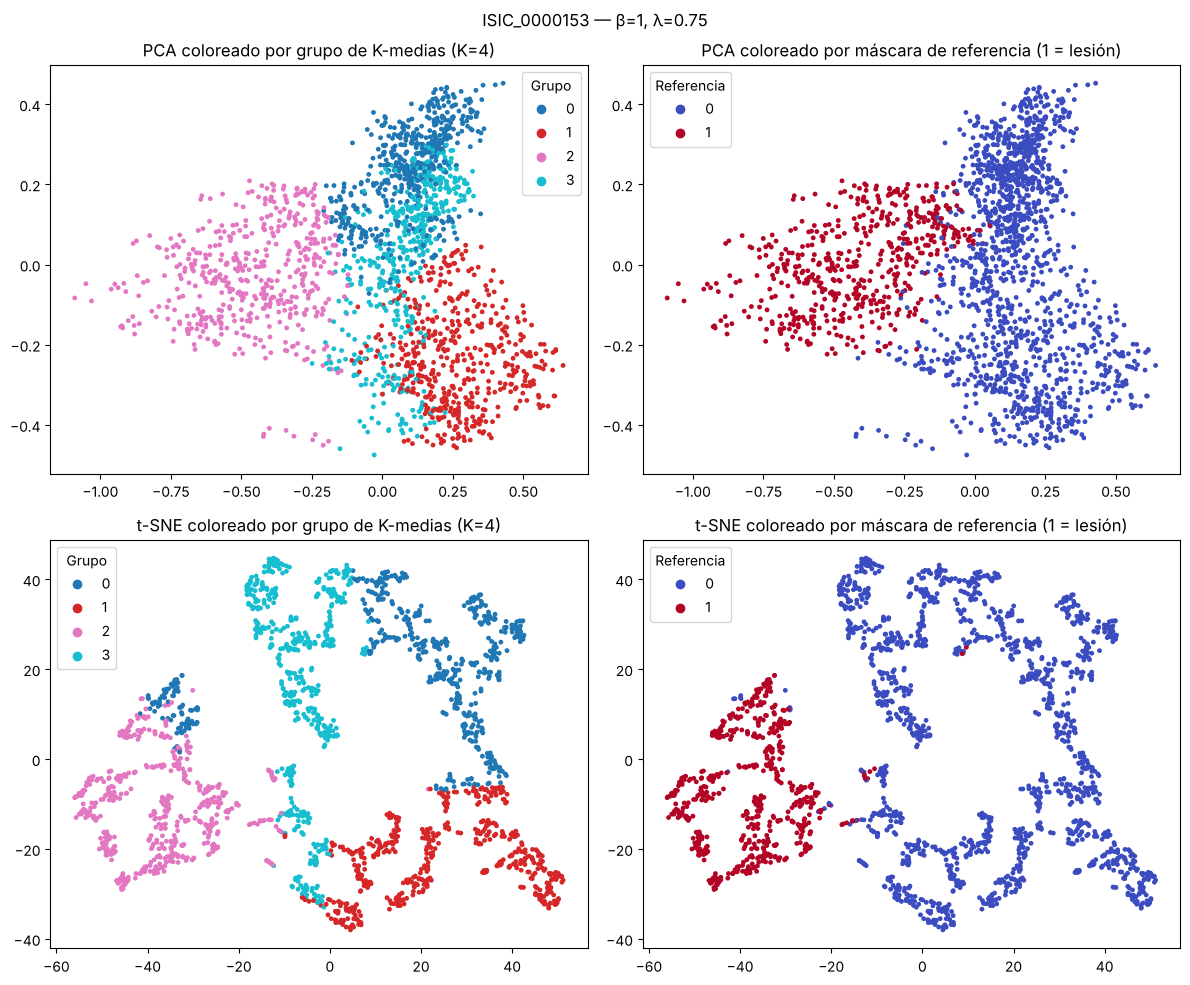

In [53]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10), layout='tight')
for i, (proy, nombre_proy) in enumerate([(X_pca, 'PCA'), (X_tsne, 't-SNE')]):
    sc = ax[i, 0].scatter(proy[:, 0], proy[:, 1], c=r_bA['etiquetas'][X_idx_sample], cmap='tab10', s=6)
    ax[i, 0].legend(*sc.legend_elements(), title='Grupo')
    ax[i, 0].set_title(f'{nombre_proy} coloreado por grupo de K-medias (K={r_bA["K"]})')
    sc = ax[i, 1].scatter(proy[:, 0], proy[:, 1], c=ref_bA[X_idx_sample], cmap='coolwarm', s=6)
    ax[i, 1].legend(*sc.legend_elements(), title='Referencia')
    ax[i, 1].set_title(f'{nombre_proy} coloreado por máscara de referencia (1 = lesión)')
plt.suptitle(f'{nombre_bA} — {nombre_config(CONFIG_FINAL["beta"], CONFIG_FINAL["lam"])}')
plt.show()

In [54]:
pd.DataFrame(pca.components_, columns=columnas, index=['Componente 1', 'Componente 2']).round(3)

,β·R,β·G,β·B,λ·x,λ·y
Componente 1,0.523,0.570,0.611,-0.011,0.169
Componente 2,-0.059,-0.015,-0.007,0.945,0.321


*En PCA, la primera componente mide el brillo del píxel y la segunda su posición horizontal; juntas conservan el 75% de la varianza. La lesión queda en la zona oscura y casi toda cae en un solo grupo, mientras que la piel se reparte en tres grupos según su posición, lo que explica por qué el V-measure baja al usar la posición. En t-SNE la lesión forma una región separada, pero algunos de sus píxeles, los del centro claro, quedaron en un grupo de piel. Como limitación, PCA pierde el 25% de la información y en t-SNE las distancias entre regiones no se pueden interpretar.*

### 12.2 Bono B. Investigación y comparación con mean shift

*Mean shift no está en las prácticas, así que se usó la documentación de scikit-learn. El algoritmo mueve cada centroide hacia el promedio de los puntos que tiene alrededor, hasta encontrar las zonas más densas de los datos. El tamaño de ese alrededor es el ancho de banda, si es pequeño se forman muchos grupos y si es grande quedan pocos. Por eso no hay que fijar K, porque el número de grupos depende del ancho de banda.*

*Se probó en ISIC_0000085 reducida a 64 píxeles de ancho, porque mean shift es más lento que K-medias. El ancho de banda se estimó con `estimate_bandwidth` para tres cuantiles (0,1, 0,2 y 0,3), como en el ejemplo de la documentación, y la máscara se construyó con el mismo criterio del grupo más oscuro.*

In [55]:
ANCHO_MS = 64
nombre_bB = 'ISIC_0000085'
idx_bB = nombres_ajuste.index(nombre_bB)
img_bB = reducir_imagen(imgs_ajuste[idx_bB], ANCHO_MS)
mask_bB = preparar_mascara(masks_ajuste[idx_bB], ANCHO_MS)

pipe.set_params(pesos__kw_args={'beta': CONFIG_FINAL['beta'], 'lam': CONFIG_FINAL['lam']})
X_bB = pipe[:-1].fit_transform(img_bB)
print(f"Imagen {nombre_bB} reducida a {img_bB.shape[1]}x{img_bB.shape[0]}: {X_bB.shape[0]} píxeles")

Imagen ISIC_0000085 reducida a 64x48: 3072 píxeles


In [56]:
# K-medias con el método completo (búsqueda de K por silueta) a la misma resolución
inicio = time.time()
r_km = segmentar(img_bB, CONFIG_FINAL['beta'], CONFIG_FINAL['lam'])
t_km = time.time() - inicio

filas_ms = [{'método': f"K-medias (K={r_km['K']} por silueta)", 'ancho de banda': np.nan, 'grupos': r_km['K'],
             'tiempo (s)': t_km, 'dice': f1_score(mask_bB.ravel(), r_km['mascara'].ravel())}]
etiquetas_ms = {}

# Mean shift con el ancho de banda estimado a partir de distintos cuantiles
for q in [0.1, 0.2, 0.3]:
    inicio = time.time()
    bandwidth = estimate_bandwidth(X_bB, quantile=q, n_samples=500, random_state=SEMILLA)
    ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
    ms.fit(X_bB)
    t_ms = time.time() - inicio
    etiquetas_ms[q] = ms.labels_
    mask_ms = construir_mascara(img_bB, ms.labels_)
    filas_ms.append({'método': f'Mean shift (quantile={q})', 'ancho de banda': bandwidth,
                     'grupos': len(np.unique(ms.labels_)), 'tiempo (s)': t_ms,
                     'dice': f1_score(mask_bB.ravel(), mask_ms.ravel())})

df_ms = pd.DataFrame(filas_ms)
df_ms.round(3)

,método,ancho de banda,grupos,tiempo (s),dice
0,K-medias (K=2 por silueta),NaN,2,0.266,0.890
1,Mean shift (quantile=0.1),0.244,7,0.590,0.537
2,Mean shift (quantile=0.2),0.335,3,0.531,0.914
3,Mean shift (quantile=0.3),0.413,2,0.234,0.908


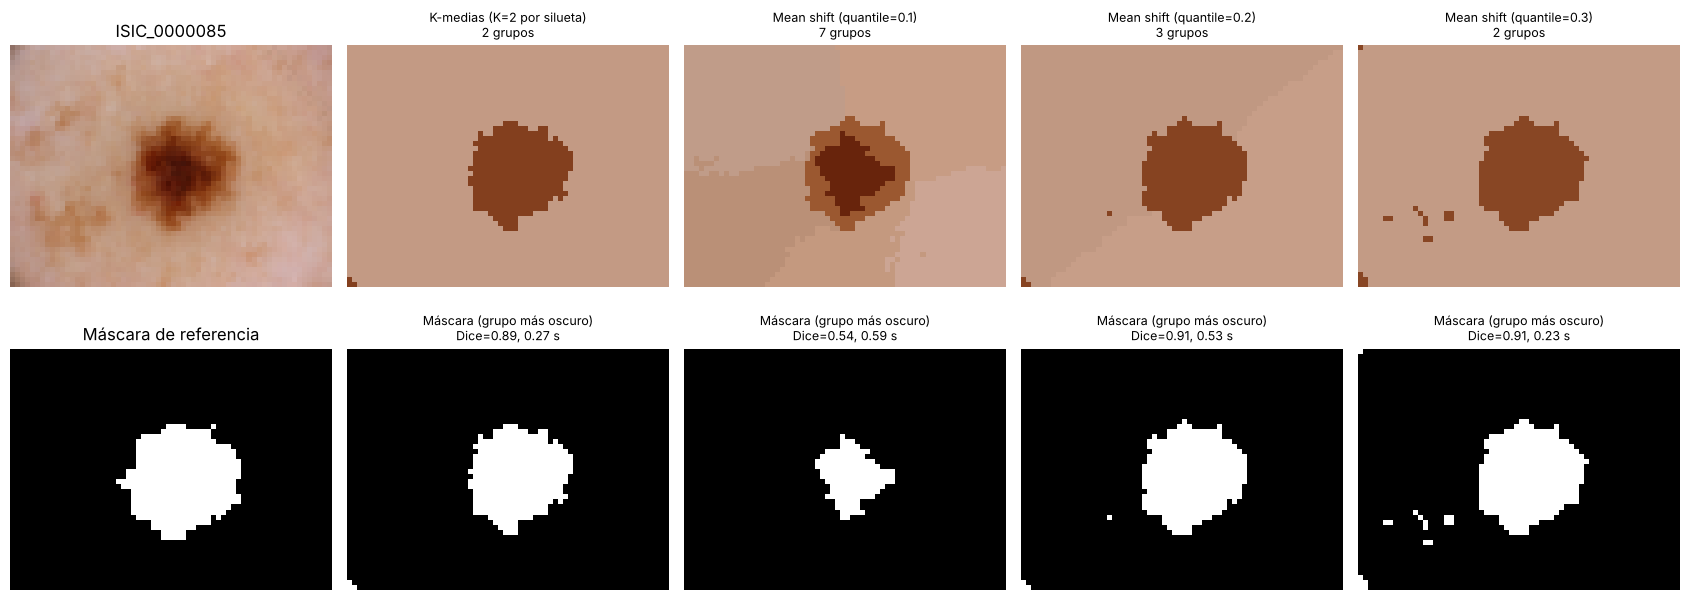

In [57]:
fig, ax = plt.subplots(2, 5, figsize=(17, 6.5), layout='tight')
ax[0, 0].imshow(img_bB); ax[0, 0].set_title(nombre_bB)
ax[1, 0].imshow(mask_bB, cmap='gray'); ax[1, 0].set_title('Máscara de referencia')
paneles = [(r_km['etiquetas'], df_ms.loc[0])] + [(etiquetas_ms[q], df_ms.loc[i + 1]) for i, q in enumerate([0.1, 0.2, 0.3])]
for j, (etiq, fila) in enumerate(paneles):
    ax[0, j + 1].imshow(imagen_segmentada(img_bB, etiq))
    ax[0, j + 1].set_title(f"{fila['método']}\n{int(fila['grupos'])} grupos", fontsize=9)
    ax[1, j + 1].imshow(construir_mascara(img_bB, etiq), cmap='gray')
    ax[1, j + 1].set_title(f"Máscara (grupo más oscuro)\nDice={fila['dice']:.2f}, {fila['tiempo (s)']:.2f} s", fontsize=9)
for a in ax.flat:
    a.axis('off')
plt.show()

*Con el ancho de banda más pequeño mean shift forma 7 grupos, la lesión se divide en varios tonos y el Dice cae a 0,54. Con los otros dos forma 2 o 3 grupos y el Dice sube a 0,91, un poco más que K-medias (0,89). Los tiempos son parecidos, menos de un segundo en ambos casos. En conclusión, mean shift evita elegir K, pero obliga a elegir el ancho de banda, y el resultado depende mucho de él.*